# Notebook 1: Data Ingestion, Cleaning, EDA & Feature Engineering

**Project:** Traders Behavior Analysis (`Traders-Behavior-Analysis`)  
**Scope:** Phases 1–4 of [`docs/PLAN.md`](docs/PLAN.md) — Data Audit, Cleaning & Alignment, Exploratory Data Analysis (EDA), and Feature Engineering.  
**Environment:** Local Jupyter Notebook (reproducible relative paths; no Colab dependencies).

---

## 0. Configuration, Reproducibility & Artifact Helpers

All processed CSVs are exported to `csv_files/` and all visual outputs (plots + tabular summary snapshots) are saved to `outputs/` at 300 DPI.

In [6]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Deterministic seed
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Resolve project directories robustly regardless of working directory
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "csv_files").exists() and (PROJECT_ROOT.parent / "csv_files").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

CSV_DIR = PROJECT_ROOT / "csv_files"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
CSV_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Consistent publication-quality visual styling
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "figure.figsize": (12, 6),
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "legend.frameon": True,
})


def save_fig(fig: plt.Figure, filename: str, close: bool = False) -> Path:
    """Save a matplotlib figure cleanly to outputs/ at 300 DPI."""
    out_path = OUTPUT_DIR / filename
    fig.savefig(out_path, dpi=300, bbox_inches="tight", facecolor="white")
    print(f"[Saved Image] {out_path.relative_to(PROJECT_ROOT)}")
    if close:
        plt.close(fig)
    return out_path


def save_table_image(
    df: pd.DataFrame,
    filename: str,
    title: str = "",
    max_rows: int = 25,
    col_width: float = 2.2,
    row_height: float = 0.45,
) -> Path:
    """Render a pandas DataFrame summary table as a crisp PNG image in outputs/."""
    view = df.head(max_rows).copy()
    n_rows, n_cols = view.shape
    fig_w = max(8, n_cols * col_width)
    fig_h = max(2.2, (n_rows + 1.8) * row_height)

    fig, ax = plt.subplots(figsize=(fig_w, fig_h))
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=13, fontweight="bold", pad=12, loc="left")

    table = ax.table(
        cellText=view.astype(str).values,
        colLabels=[str(c) for c in view.columns],
        cellLoc="center",
        loc="center",
    )
    table.auto_set_font_size(False)
    table.set_fontsize(9.5)
    table.scale(1.0, 1.4)

    for (r, c), cell in table.get_celld().items():
        if r == 0:
            cell.set_facecolor("#1f3b5c")
            cell.set_text_props(color="white", weight="bold")
        else:
            cell.set_facecolor("#f7f9fc" if r % 2 == 0 else "white")
        cell.set_edgecolor("#d0d7de")

    return save_fig(fig, filename, close=True)


def export_csv(df: pd.DataFrame, filename: str, index: bool = False) -> Path:
    """Export a DataFrame to csv_files/ with row/column logging."""
    out_path = CSV_DIR / filename
    df.to_csv(out_path, index=index)
    print(f"[Saved CSV] {out_path.relative_to(PROJECT_ROOT)} | shape={df.shape}")
    return out_path


print(f"Project Root: {PROJECT_ROOT}")
print(f"CSV Directory: {CSV_DIR}")
print(f"Output Directory: {OUTPUT_DIR}")

Project Root: c:\Users\sgogo\OneDrive\Desktop\Portfolio Projects\TBD\Bitcoin-Sentiment\Traders-Behavior-Analysis
CSV Directory: c:\Users\sgogo\OneDrive\Desktop\Portfolio Projects\TBD\Bitcoin-Sentiment\Traders-Behavior-Analysis\csv_files
Output Directory: c:\Users\sgogo\OneDrive\Desktop\Portfolio Projects\TBD\Bitcoin-Sentiment\Traders-Behavior-Analysis\outputs


---
## 1. Phase 1: Data Acquisition & Initial Schema Inspection

- Copy raw CSVs from `dataset/` into `csv_files/` (non-destructive; preserves originals in `dataset/`).
- Inspect shapes, dtypes, memory footprint, date coverage, unique counts, and missingness.
- Note raw export characteristics (e.g., scientific-notation precision loss in `Timestamp` and `Trade ID`, IST timestamps in `Timestamp IST`).
- Export audit artifacts: `csv_files/00_data_audit_summary.csv`, `outputs/01_audit_schema_summary.png`, `outputs/01_audit_missingness.png`.

In [7]:
import shutil

DATASET_DIR = PROJECT_ROOT / "dataset"
RAW_FILES = ["fear_greed_index.csv", "historical_data.csv"]

for fname in RAW_FILES:
    src = DATASET_DIR / fname
    dst = CSV_DIR / fname
    if not dst.exists():
        if not src.exists():
            raise FileNotFoundError(f"Missing raw dataset file: {src}")
        shutil.copy2(src, dst)
        print(f"[Copied] {src.relative_to(PROJECT_ROOT)} -> {dst.relative_to(PROJECT_ROOT)}")
    else:
        print(f"[Exists] {dst.relative_to(PROJECT_ROOT)}")

available_csvs = sorted(CSV_DIR.glob("*.csv"))
print("Available CSV files in csv_files/:", [p.name for p in available_csvs])

[Copied] dataset\fear_greed_index.csv -> csv_files\fear_greed_index.csv
[Copied] dataset\historical_data.csv -> csv_files\historical_data.csv
Available CSV files in csv_files/: ['fear_greed_index.csv', 'historical_data.csv']


[Saved CSV] csv_files\00_data_audit_summary.csv | shape=(20, 8)


,Dataset,Rows,Cols,Memory_MB,Exact_Duplicates,Total_Missing_Cells,Date_Range_Raw
0,fear_greed_index.csv,"2,644",4,0.35,0,0,2018-02-01 -> 2025-05-02
1,historical_data.csv,"211,224",16,107.16,0,0,See Timestamp IST (DD-MM-YYYY HH:MM)


,dataset,column,dtype,non_null,null_count,null_pct,n_unique,sample_value
0,fear_greed_index,timestamp,int64,2644,0,0.0,2644,1517463000
1,fear_greed_index,value,int64,2644,0,0.0,90,30
2,fear_greed_index,classification,str,2644,0,0.0,5,Fear
3,fear_greed_index,date,str,2644,0,0.0,2644,2018-02-01
4,historical_data,Account,str,211224,0,0.0,32,0xae5eacaf9c6b9111fd53034a602c192a04e082ed
5,historical_data,Coin,str,211224,0,0.0,246,@107
6,historical_data,Execution Price,float64,211224,0,0.0,60162,7.9769
7,historical_data,Size Tokens,float64,211224,0,0.0,59304,986.87
8,historical_data,Size USD,float64,211224,0,0.0,118493,7872.16
9,historical_data,Side,str,211224,0,0.0,2,BUY


[Saved Image] outputs\01_audit_schema_summary.png
[Saved Image] outputs\01_audit_missingness.png


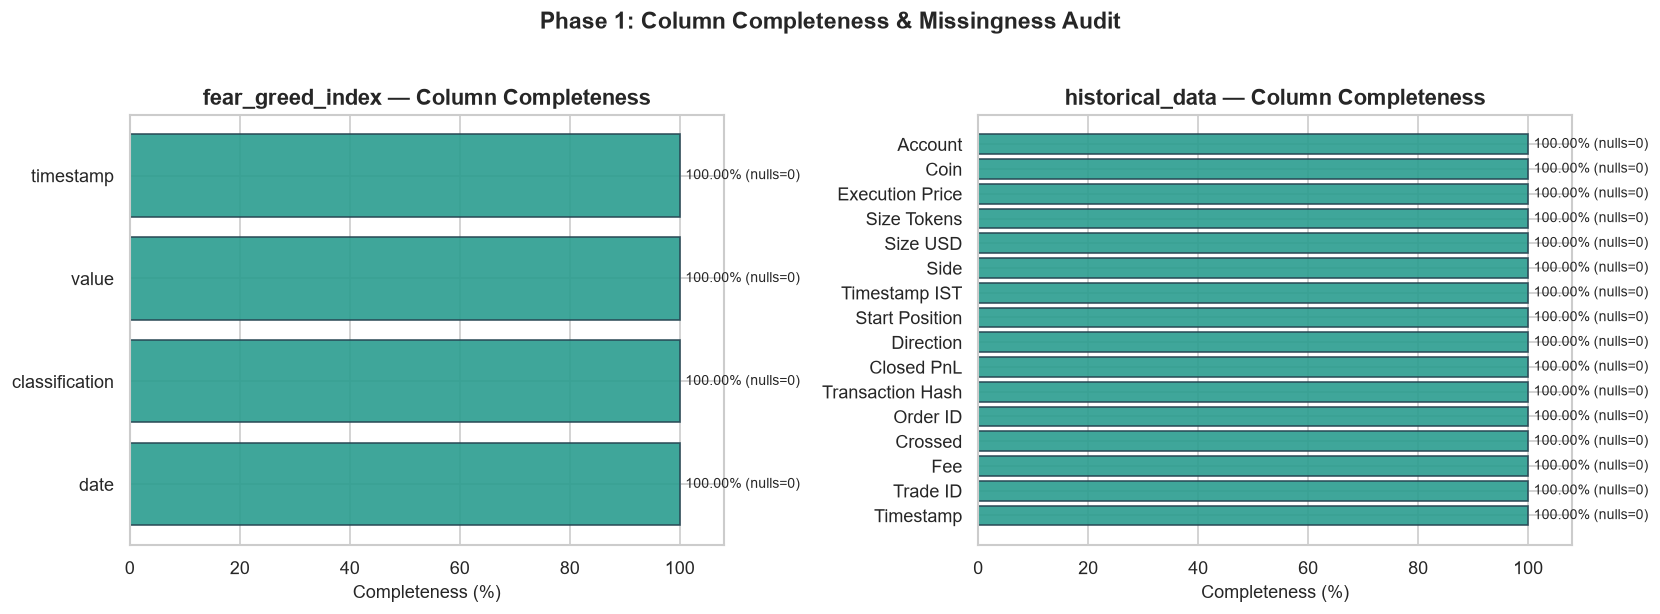

In [8]:
# Load raw datasets without altering values
raw_sentiment = pd.read_csv(CSV_DIR / "fear_greed_index.csv")
raw_trades = pd.read_csv(CSV_DIR / "historical_data.csv", low_memory=False)


def build_column_audit(df: pd.DataFrame, dataset_name: str) -> pd.DataFrame:
    """Build a per-column schema & missingness summary table."""
    records = []
    n_rows = len(df)
    for col in df.columns:
        s = df[col]
        n_null = int(s.isna().sum())
        records.append({
            "dataset": dataset_name,
            "column": col,
            "dtype": str(s.dtype),
            "non_null": int(s.notna().sum()),
            "null_count": n_null,
            "null_pct": round(100.0 * n_null / max(n_rows, 1), 4),
            "n_unique": int(s.nunique(dropna=True)),
            "sample_value": str(s.dropna().iloc[0]) if s.notna().any() else "NaN",
        })
    return pd.DataFrame(records)


audit_df = pd.concat([
    build_column_audit(raw_sentiment, "fear_greed_index"),
    build_column_audit(raw_trades, "historical_data"),
], ignore_index=True)

export_csv(audit_df, "00_data_audit_summary.csv")

# Dataset-level overview card
overview_df = pd.DataFrame([
    {
        "Dataset": "fear_greed_index.csv",
        "Rows": f"{len(raw_sentiment):,}",
        "Cols": raw_sentiment.shape[1],
        "Memory_MB": round(raw_sentiment.memory_usage(deep=True).sum() / 1e6, 2),
        "Exact_Duplicates": int(raw_sentiment.duplicated().sum()),
        "Total_Missing_Cells": int(raw_sentiment.isna().sum().sum()),
        "Date_Range_Raw": f"{raw_sentiment['date'].min()} -> {raw_sentiment['date'].max()}",
    },
    {
        "Dataset": "historical_data.csv",
        "Rows": f"{len(raw_trades):,}",
        "Cols": raw_trades.shape[1],
        "Memory_MB": round(raw_trades.memory_usage(deep=True).sum() / 1e6, 2),
        "Exact_Duplicates": int(raw_trades.duplicated().sum()),
        "Total_Missing_Cells": int(raw_trades.isna().sum().sum()),
        "Date_Range_Raw": "See Timestamp IST (DD-MM-YYYY HH:MM)",
    },
])

display(overview_df)
display(audit_df)

save_table_image(
    overview_df,
    "01_audit_schema_summary.png",
    title="Phase 1: Raw Dataset Schema & Integrity Overview",
    col_width=2.5,
)

# Missingness / Completeness Visual
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, sub) in zip(axes, audit_df.groupby("dataset", sort=False)):
    completeness = 100.0 - sub["null_pct"]
    colors = ["#2a9d8f" if v == 100.0 else "#e76f51" for v in completeness]
    ax.barh(sub["column"], completeness, color=colors, edgecolor="#264653", alpha=0.9)
    ax.set_xlim(0, 108)
    ax.set_xlabel("Completeness (%)")
    ax.set_title(f"{name} — Column Completeness")
    ax.invert_yaxis()
    for idx, (pct, n_null) in enumerate(zip(completeness, sub["null_count"])):
        ax.text(min(pct + 1, 101), idx, f"{pct:.2f}% (nulls={n_null})", va="center", fontsize=8.5)

fig.suptitle("Phase 1: Column Completeness & Missingness Audit", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
save_fig(fig, "01_audit_missingness.png")
plt.show()

---
## 2. Phase 2: Data Cleaning, Normalization & Temporal Alignment

### Key Cleaning Rules & Verification Steps
1. **Column Normalization:** Convert all headers to lowercase `snake_case`.
2. **Timestamp Parsing & Timezone Alignment:**
   - In `historical_data.csv`, the `Timestamp` column is stored in truncated scientific notation (e.g., `1.73E+12`), losing ~10 digits of precision. We **flag** it as `timestamp_raw_sci` and reconstruct exact timestamps from `Timestamp IST` (`%d-%m-%Y %H:%M`, localized to `Asia/Kolkata` and converted to `UTC`).
   - Extract both `trade_date_utc` and `trade_date_ist` so we can audit midnight-boundary differences and align with `fear_greed_index.csv` (`date`).
3. **Type Casting & Categorical Normalization:**
   - Coerce numeric columns safely (`execution_price`, `size_tokens`, `size_usd`, `start_position`, `closed_pnl`, `fee`, `value`) and inspect any parse failures.
   - Standardize `side`, `direction`, `crossed` (bool), and ordered `classification` (`Extreme Fear` < `Fear` < `Neutral` < `Greed` < `Extreme Greed`).
4. **Deduplication & Quality Flags (Non-Destructive):**
   - Remove only **exact full-row duplicates** (if any); preserve distinct partial fills that share an `order_id` or `transaction_hash`.
   - Add explicit diagnostic flags (`is_spot_index`, `is_closing_trade`, `is_maker`, `is_negative_fee`, `notional_mismatch_flag`, `extreme_size_flag`, `extreme_pnl_flag`) rather than silently dropping large whale trades.
5. **Temporal Merge & Exports:**
   - Left-join cleaned trades onto cleaned daily sentiment (plus 1-day lagged sentiment `sentiment_value_lag1`, `sentiment_class_lag1`) on `trade_date_utc`.
   - Verify zero row explosion, audit unmatched dates (if any), export `01_clean_sentiment.csv`, `01_clean_trader_data.csv`, `02_merged_trader_sentiment.csv`, `02_phase2_cleaning_summary.csv`, and save `outputs/01_audit_cleaning_funnel.png`, `outputs/01_audit_temporal_coverage.png`, `outputs/01_audit_phase2_summary_table.png`.

In [9]:
# 2.1 Clean & normalize market sentiment dataset
def to_snake_case(col: str) -> str:
    return (
        col.strip()
        .lower()
        .replace(" ", "_")
        .replace("-", "_")
    )


SENTIMENT_ORDER = ["Extreme Fear", "Fear", "Neutral", "Greed", "Extreme Greed"]

clean_sent = raw_sentiment.copy()
clean_sent.columns = [to_snake_case(c) for c in clean_sent.columns]

n_sent_raw = len(clean_sent)
clean_sent["classification"] = clean_sent["classification"].astype(str).str.strip()
clean_sent["value"] = pd.to_numeric(clean_sent["value"], errors="coerce")
clean_sent["sentiment_date"] = pd.to_datetime(clean_sent["date"], format="%Y-%m-%d", errors="coerce")
clean_sent["timestamp_utc"] = pd.to_datetime(clean_sent["timestamp"], unit="s", utc=True, errors="coerce")

# Deduplicate on sentiment_date if needed
n_sent_date_dups = int(clean_sent["sentiment_date"].duplicated().sum())
clean_sent = (
    clean_sent.dropna(subset=["sentiment_date", "value", "classification"])
    .drop_duplicates(subset=["sentiment_date"], keep="last")
    .sort_values("sentiment_date")
    .reset_index(drop=True)
)

# Check calendar continuity (missing days in the sentiment series)
full_cal = pd.date_range(clean_sent["sentiment_date"].min(), clean_sent["sentiment_date"].max(), freq="D")
missing_sent_dates = sorted(set(full_cal) - set(clean_sent["sentiment_date"]))

# Coarse 3-bucket regime + ordered encoding + lagged sentiment
coarse_map = {
    "Extreme Fear": "Fear",
    "Fear": "Fear",
    "Neutral": "Neutral",
    "Greed": "Greed",
    "Extreme Greed": "Greed",
}
clean_sent["regime_coarse"] = clean_sent["classification"].map(coarse_map)
clean_sent["regime_score_ord"] = clean_sent["classification"].map(
    {k: i for i, k in enumerate(SENTIMENT_ORDER)}
)
clean_sent["sentiment_value_lag1"] = clean_sent["value"].shift(1)
clean_sent["sentiment_class_lag1"] = clean_sent["classification"].shift(1)
clean_sent["sentiment_delta_1d"] = clean_sent["value"].diff(1)
clean_sent["sentiment_date_str"] = clean_sent["sentiment_date"].dt.strftime("%Y-%m-%d")

print(f"Sentiment raw rows: {n_sent_raw:,} | Clean rows: {len(clean_sent):,} | Date duplicates: {n_sent_date_dups}")
print(f"Sentiment date range: {clean_sent['sentiment_date_str'].min()} -> {clean_sent['sentiment_date_str'].max()}")
print(f"Missing calendar days in sentiment index: {len(missing_sent_dates)}")
if missing_sent_dates:
    print("Sample missing sentiment dates:", [d.strftime("%Y-%m-%d") for d in missing_sent_dates[:10]])
print("Classification counts:\n", clean_sent["classification"].value_counts())

export_csv(clean_sent, "01_clean_sentiment.csv")

Sentiment raw rows: 2,644 | Clean rows: 2,644 | Date duplicates: 0
Sentiment date range: 2018-02-01 -> 2025-05-02
Missing calendar days in sentiment index: 4
Sample missing sentiment dates: ['2018-04-14', '2018-04-15', '2018-04-16', '2024-10-26']
Classification counts:
 classification
Fear             781
Greed            633
Extreme Fear     508
Neutral          396
Extreme Greed    326
Name: count, dtype: int64
[Saved CSV] csv_files\01_clean_sentiment.csv | shape=(2644, 12)


WindowsPath('c:/Users/sgogo/OneDrive/Desktop/Portfolio Projects/TBD/Bitcoin-Sentiment/Traders-Behavior-Analysis/csv_files/01_clean_sentiment.csv')

In [10]:
# 2.2 Clean & normalize historical trader dataset
clean_trades = raw_trades.copy()
clean_trades.columns = [to_snake_case(c) for c in clean_trades.columns]
clean_trades = clean_trades.rename(columns={"timestamp": "timestamp_raw_sci"})

n_trades_raw = len(clean_trades)

# Clean string identifiers & categoricals
for str_col in ["account", "coin", "side", "direction", "transaction_hash"]:
    clean_trades[str_col] = clean_trades[str_col].astype(str).str.strip()

clean_trades["side"] = clean_trades["side"].str.upper()

# Safe boolean parsing for 'crossed' (Taker = True, Maker = False)
clean_trades["crossed"] = (
    clean_trades["crossed"]
    .astype(str)
    .str.strip()
    .str.upper()
    .map({"TRUE": True, "FALSE": False})
)

# Safe numeric casting
num_cols = ["execution_price", "size_tokens", "size_usd", "start_position", "closed_pnl", "fee"]
coerce_failures = {}
for col in num_cols:
    before_na = int(clean_trades[col].isna().sum())
    clean_trades[col] = pd.to_numeric(clean_trades[col], errors="coerce")
    after_na = int(clean_trades[col].isna().sum())
    coerce_failures[col] = after_na - before_na

print("Numeric coercion failures:", coerce_failures)

# Parse Timestamp IST (%d-%m-%Y %H:%M) -> localized IST -> UTC
dt_ist_naive = pd.to_datetime(clean_trades["timestamp_ist"], format="%d-%m-%Y %H:%M", errors="coerce")
# Fallback for any rows that might include seconds
mask_unparsed = dt_ist_naive.isna() & clean_trades["timestamp_ist"].notna()
if mask_unparsed.any():
    dt_ist_naive.loc[mask_unparsed] = pd.to_datetime(
        clean_trades.loc[mask_unparsed, "timestamp_ist"], dayfirst=True, errors="coerce"
    )

n_ts_failed = int(dt_ist_naive.isna().sum())
print(f"Timestamp IST parse failures: {n_ts_failed}")

dt_ist = dt_ist_naive.dt.tz_localize("Asia/Kolkata", ambiguous="infer", nonexistent="shift_forward")
dt_utc = dt_ist.dt.tz_convert("UTC")

clean_trades["timestamp_ist_dt"] = dt_ist_naive
clean_trades["timestamp_utc"] = dt_utc
clean_trades["trade_date_utc"] = dt_utc.dt.strftime("%Y-%m-%d")
clean_trades["trade_date_ist"] = dt_ist_naive.dt.strftime("%Y-%m-%d")
clean_trades["hour_utc"] = dt_utc.dt.hour
clean_trades["day_of_week_utc"] = dt_utc.dt.day_name()

# Exact full-row duplicates check (before dropping)
n_exact_dups = int(clean_trades.duplicated().sum())
clean_trades = clean_trades.drop_duplicates().reset_index(drop=True)

# Drop rows missing critical timestamp or execution fields (if any)
n_before_critical_drop = len(clean_trades)
clean_trades = clean_trades.dropna(subset=["timestamp_utc", "execution_price", "size_tokens", "size_usd"]).reset_index(drop=True)
n_dropped_critical = n_before_critical_drop - len(clean_trades)

# Non-destructive diagnostic & domain flags
clean_trades["is_spot_index"] = clean_trades["coin"].str.startswith("@")
clean_trades["is_maker"] = ~clean_trades["crossed"].fillna(False)
clean_trades["is_closing_trade"] = clean_trades["closed_pnl"] != 0
clean_trades["is_negative_fee"] = clean_trades["fee"] < 0
clean_trades["computed_notional_usd"] = clean_trades["execution_price"] * clean_trades["size_tokens"]
clean_trades["notional_abs_diff"] = (clean_trades["size_usd"] - clean_trades["computed_notional_usd"]).abs()
clean_trades["notional_mismatch_flag"] = clean_trades["notional_abs_diff"] > np.maximum(1.0, 0.01 * clean_trades["size_usd"])

size_p999 = clean_trades["size_usd"].quantile(0.999)
pnl_abs_p999 = clean_trades["closed_pnl"].abs().quantile(0.999)
clean_trades["extreme_size_flag"] = clean_trades["size_usd"] > size_p999
clean_trades["extreme_pnl_flag"] = clean_trades["closed_pnl"].abs() > pnl_abs_p999
clean_trades["date_shifted_ist_to_utc"] = clean_trades["trade_date_ist"] != clean_trades["trade_date_utc"]

print(f"Trader raw rows: {n_trades_raw:,} | Exact dups removed: {n_exact_dups:,} | Critical NaNs dropped: {n_dropped_critical:,} | Clean rows: {len(clean_trades):,}")
print(f"UTC date range: {clean_trades['trade_date_utc'].min()} -> {clean_trades['trade_date_utc'].max()}")
print(f"Unique accounts: {clean_trades['account'].nunique():,} | Unique coins: {clean_trades['coin'].nunique():,}")
print(f"Trades shifting calendar day IST -> UTC: {int(clean_trades['date_shifted_ist_to_utc'].sum()):,} ({100*clean_trades['date_shifted_ist_to_utc'].mean():.2f}%)")
print(f"Notional mismatch flags (>max($1, 1%)): {int(clean_trades['notional_mismatch_flag'].sum()):,}")
print("Direction value counts:\n", clean_trades["direction"].value_counts())

export_csv(clean_trades, "01_clean_trader_data.csv")

Numeric coercion failures: {'execution_price': 0, 'size_tokens': 0, 'size_usd': 0, 'start_position': 0, 'closed_pnl': 0, 'fee': 0}
Timestamp IST parse failures: 0
Trader raw rows: 211,224 | Exact dups removed: 0 | Critical NaNs dropped: 0 | Clean rows: 211,224
UTC date range: 2023-04-30 -> 2025-05-01
Unique accounts: 32 | Unique coins: 246
Trades shifting calendar day IST -> UTC: 53,322 (25.24%)
Notional mismatch flags (>max($1, 1%)): 0
Direction value counts:
 direction
Open Long                    49895
Close Long                   48678
Open Short                   39741
Close Short                  36013
Sell                         19902
Buy                          16716
Spot Dust Conversion           142
Short > Long                    70
Long > Short                    57
Auto-Deleveraging                8
Liquidated Isolated Short        1
Settlement                       1
Name: count, dtype: int64
[Saved CSV] csv_files\01_clean_trader_data.csv | shape=(211224, 32)


WindowsPath('c:/Users/sgogo/OneDrive/Desktop/Portfolio Projects/TBD/Bitcoin-Sentiment/Traders-Behavior-Analysis/csv_files/01_clean_trader_data.csv')

In [11]:
# 2.3 Temporal alignment & merge with market sentiment
sent_merge_cols = [
    "sentiment_date_str",
    "value",
    "classification",
    "regime_coarse",
    "regime_score_ord",
    "sentiment_value_lag1",
    "sentiment_class_lag1",
    "sentiment_delta_1d",
]

merged_df = clean_trades.merge(
    clean_sent[sent_merge_cols].rename(columns={
        "sentiment_date_str": "trade_date_utc",
        "value": "sentiment_value",
        "classification": "sentiment_class",
    }),
    on="trade_date_utc",
    how="left",
    validate="many_to_one",
)

# Assert row count preservation
assert len(merged_df) == len(clean_trades), (
    f"Row count changed on merge: {len(clean_trades)} -> {len(merged_df)}"
)

n_unmatched_utc = int(merged_df["sentiment_class"].isna().sum())
unmatched_dates_utc = sorted(merged_df.loc[merged_df["sentiment_class"].isna(), "trade_date_utc"].unique())

# Compare overlap if joined on IST date instead (diagnostic only)
ist_matched = clean_trades["trade_date_ist"].isin(set(clean_sent["sentiment_date_str"]))
n_unmatched_ist = int((~ist_matched).sum())

print(f"Merged shape: {merged_df.shape}")
print(f"Matched on UTC date: {len(merged_df) - n_unmatched_utc:,} / {len(merged_df):,} (Unmatched: {n_unmatched_utc:,})")
if unmatched_dates_utc:
    print("Unmatched UTC dates:", unmatched_dates_utc)
print(f"Diagnostic — Unmatched if joined on IST date: {n_unmatched_ist:,}")

export_csv(merged_df, "02_merged_trader_sentiment.csv")

Merged shape: (211224, 39)
Matched on UTC date: 211,224 / 211,224 (Unmatched: 0)
Diagnostic — Unmatched if joined on IST date: 6
[Saved CSV] csv_files\02_merged_trader_sentiment.csv | shape=(211224, 39)


WindowsPath('c:/Users/sgogo/OneDrive/Desktop/Portfolio Projects/TBD/Bitcoin-Sentiment/Traders-Behavior-Analysis/csv_files/02_merged_trader_sentiment.csv')

,Metric,Value
0,Raw Sentiment Rows,"2,644"
1,Clean Sentiment Rows,"2,644"
2,Missing Sentiment Calendar Days,4
3,Sentiment Date Window,2018-02-01 to 2025-05-02
4,Raw Trader Rows,"211,224"
5,Exact Duplicate Trader Rows Removed,0
6,Critical Null Rows Dropped,0
7,Clean & Merged Trader Rows,"211,224"
8,Trader UTC Date Window,2023-04-30 to 2025-05-01
9,Unique Accounts / Unique Coins,32 / 246


[Saved CSV] csv_files\02_phase2_cleaning_summary.csv | shape=(14, 2)
[Saved Image] outputs\01_audit_phase2_summary_table.png
[Saved Image] outputs\01_audit_cleaning_funnel.png


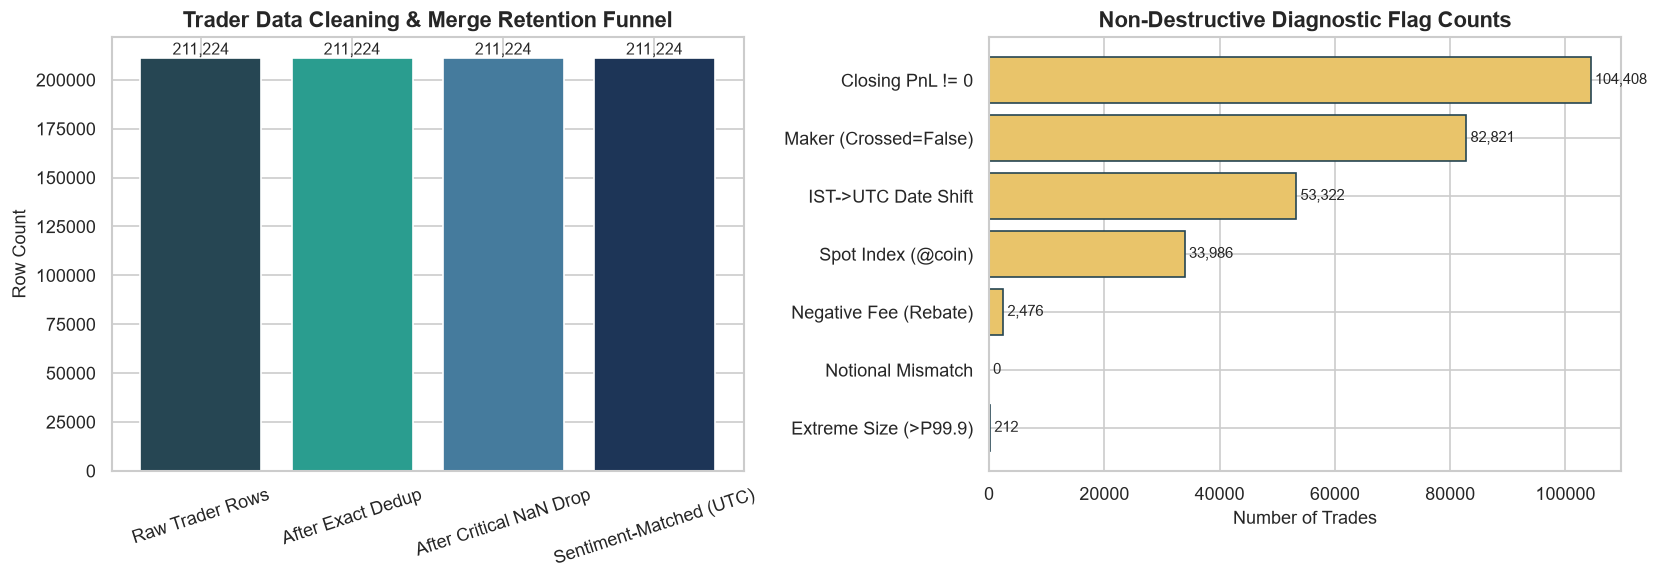

[Saved Image] outputs\01_audit_temporal_coverage.png


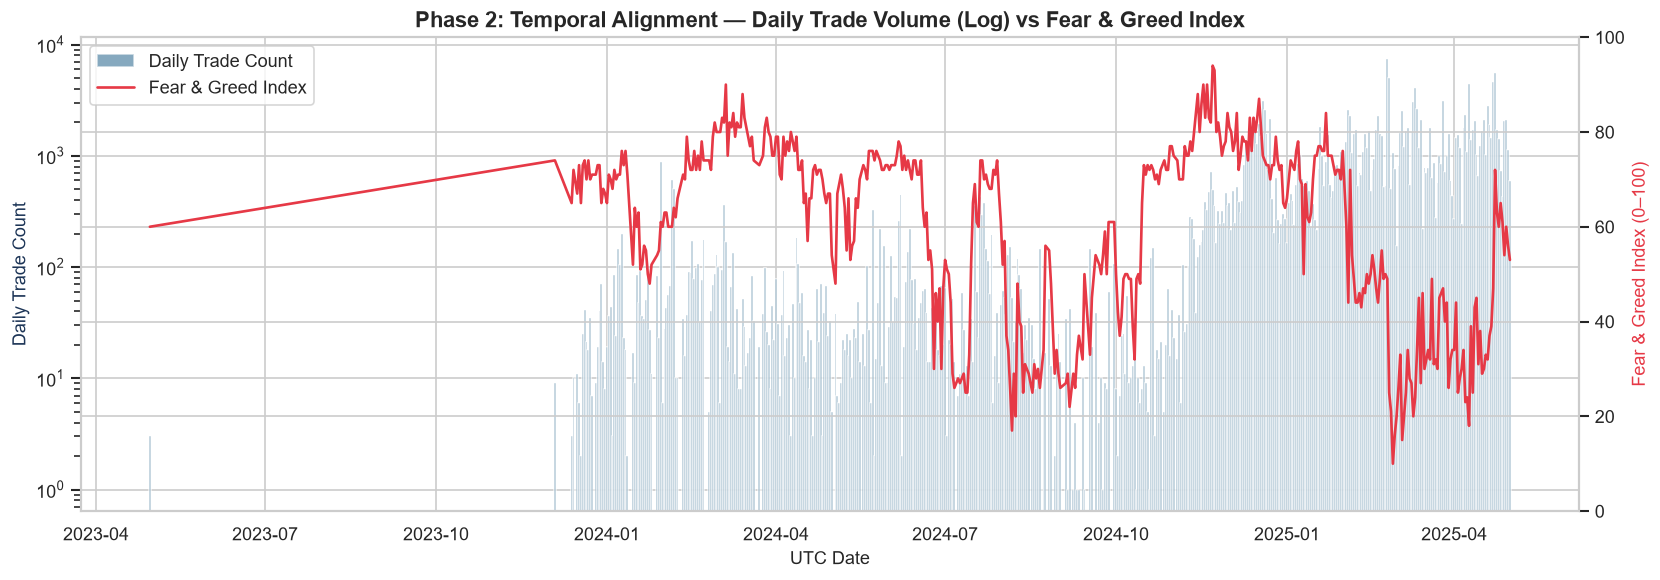

In [12]:
# 2.4 Phase 2 Summary Table & Audit Visuals
phase2_summary = pd.DataFrame([
    {"Metric": "Raw Sentiment Rows", "Value": f"{n_sent_raw:,}"},
    {"Metric": "Clean Sentiment Rows", "Value": f"{len(clean_sent):,}"},
    {"Metric": "Missing Sentiment Calendar Days", "Value": f"{len(missing_sent_dates):,}"},
    {"Metric": "Sentiment Date Window", "Value": f"{clean_sent['sentiment_date_str'].min()} to {clean_sent['sentiment_date_str'].max()}"},
    {"Metric": "Raw Trader Rows", "Value": f"{n_trades_raw:,}"},
    {"Metric": "Exact Duplicate Trader Rows Removed", "Value": f"{n_exact_dups:,}"},
    {"Metric": "Critical Null Rows Dropped", "Value": f"{n_dropped_critical:,}"},
    {"Metric": "Clean & Merged Trader Rows", "Value": f"{len(merged_df):,}"},
    {"Metric": "Trader UTC Date Window", "Value": f"{merged_df['trade_date_utc'].min()} to {merged_df['trade_date_utc'].max()}"},
    {"Metric": "Unique Accounts / Unique Coins", "Value": f"{merged_df['account'].nunique():,} / {merged_df['coin'].nunique():,}"},
    {"Metric": "Trades Matched to Sentiment (UTC)", "Value": f"{len(merged_df) - n_unmatched_utc:,} ({100*(len(merged_df)-n_unmatched_utc)/len(merged_df):.2f}%)"},
    {"Metric": "Trades Shifting Date IST -> UTC", "Value": f"{int(merged_df['date_shifted_ist_to_utc'].sum()):,} ({100*merged_df['date_shifted_ist_to_utc'].mean():.2f}%)"},
    {"Metric": "Spot Index Trades (@coin)", "Value": f"{int(merged_df['is_spot_index'].sum()):,} ({100*merged_df['is_spot_index'].mean():.2f}%)"},
    {"Metric": "Closing / Realized-PnL Trades", "Value": f"{int(merged_df['is_closing_trade'].sum()):,} ({100*merged_df['is_closing_trade'].mean():.2f}%)"},
])

display(phase2_summary)
export_csv(phase2_summary, "02_phase2_cleaning_summary.csv")
save_table_image(
    phase2_summary,
    "01_audit_phase2_summary_table.png",
    title="Phase 2: Cleaning, Alignment & Merge Audit Summary",
    col_width=4.5,
)

# Figure A: Cleaning Funnel & Diagnostic Flags
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

funnel_labels = [
    "Raw Trader Rows",
    "After Exact Dedup",
    "After Critical NaN Drop",
    "Sentiment-Matched (UTC)",
]
funnel_vals = [
    n_trades_raw,
    n_trades_raw - n_exact_dups,
    len(clean_trades),
    len(merged_df) - n_unmatched_utc,
]
bars = axes[0].bar(funnel_labels, funnel_vals, color=["#264653", "#2a9d8f", "#457b9d", "#1d3557"])
axes[0].set_title("Trader Data Cleaning & Merge Retention Funnel")
axes[0].set_ylabel("Row Count")
axes[0].tick_params(axis="x", rotation=18)
for bar, val in zip(bars, funnel_vals):
    axes[0].text(bar.get_x() + bar.get_width() / 2, val, f"{val:,}", ha="center", va="bottom", fontsize=9.5)

flag_counts = {
    "Closing PnL != 0": int(merged_df["is_closing_trade"].sum()),
    "Maker (Crossed=False)": int(merged_df["is_maker"].sum()),
    "IST->UTC Date Shift": int(merged_df["date_shifted_ist_to_utc"].sum()),
    "Spot Index (@coin)": int(merged_df["is_spot_index"].sum()),
    "Negative Fee (Rebate)": int(merged_df["is_negative_fee"].sum()),
    "Notional Mismatch": int(merged_df["notional_mismatch_flag"].sum()),
    "Extreme Size (>P99.9)": int(merged_df["extreme_size_flag"].sum()),
}
axes[1].barh(list(flag_counts.keys()), list(flag_counts.values()), color="#e9c46a", edgecolor="#264653")
axes[1].invert_yaxis()
axes[1].set_title("Non-Destructive Diagnostic Flag Counts")
axes[1].set_xlabel("Number of Trades")
for idx, val in enumerate(flag_counts.values()):
    axes[1].text(val, idx, f" {val:,}", va="center", fontsize=9)

plt.tight_layout()
save_fig(fig, "01_audit_cleaning_funnel.png")
plt.show()

# Figure B: Temporal Coverage — Daily Trade Volume vs Sentiment Overlay
daily_cov = (
    merged_df.groupby("trade_date_utc", as_index=False)
    .agg(
        trade_count=("account", "size"),
        notional_usd=("size_usd", "sum"),
        sentiment_value=("sentiment_value", "first"),
    )
)
daily_cov["trade_date_dt"] = pd.to_datetime(daily_cov["trade_date_utc"])
daily_cov = daily_cov.sort_values("trade_date_dt")

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.bar(daily_cov["trade_date_dt"], daily_cov["trade_count"], color="#457b9d", alpha=0.65, width=1.0, label="Daily Trade Count")
ax1.set_ylabel("Daily Trade Count", color="#1d3557")
ax1.set_xlabel("UTC Date")
ax1.set_yscale("log")

ax2 = ax1.twinx()
ax2.plot(daily_cov["trade_date_dt"], daily_cov["sentiment_value"], color="#e63946", linewidth=1.6, label="Fear & Greed Index")
ax2.set_ylabel("Fear & Greed Index (0–100)", color="#e63946")
ax2.set_ylim(0, 100)

ax1.set_title("Phase 2: Temporal Alignment — Daily Trade Volume (Log) vs Fear & Greed Index")
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")
plt.tight_layout()
save_fig(fig, "01_audit_temporal_coverage.png")
plt.show()

---
## 3. Phase 3: Exploratory Data Analysis (EDA) & Visual Logging

1. **3A. Market Sentiment / Risk Regimes:** Full vs active-window regime distributions, transition matrix, streak durations (`outputs/02_eda_sentiment_*.png`).
2. **3B. Trader Activity, Volume, Concentration & Profitability:** Global KPIs table image, PnL & volume distributions, execution/side/spot-vs-perp mix, top coins, Lorenz concentration & account ranking (`outputs/03_eda_*.png`).
3. **3C. Behavior Across Regimes:** Daily-normalized activity, PnL/win-rate/profit-factor, directional bias & taker aggression, and Day×Hour heatmaps conditioned on sentiment regime (`outputs/04_eda_*.png`).
4. **3D. Correlations & Lead-Lag Analysis:** Spearman/Pearson heatmaps and exact calendar-day lead-lag relationships (`outputs/05_eda_*.png`).

In [13]:
# Ensure Phase 2 artifacts are loaded (supports resuming directly from Phase 3)
SENTIMENT_ORDER = ["Extreme Fear", "Fear", "Neutral", "Greed", "Extreme Greed"]
COARSE_ORDER = ["Fear", "Neutral", "Greed"]
REGIME_COLORS = {
    "Extreme Fear": "#b2182b",
    "Fear": "#ef8a62",
    "Neutral": "#878787",
    "Greed": "#67a9cf",
    "Extreme Greed": "#2166ac",
}

if "clean_sent" not in globals():
    clean_sent = pd.read_csv(CSV_DIR / "01_clean_sentiment.csv")
    clean_sent["sentiment_date"] = pd.to_datetime(clean_sent["sentiment_date"])

if "merged_df" not in globals():
    merged_df = pd.read_csv(CSV_DIR / "02_merged_trader_sentiment.csv", low_memory=False)

merged_df["trade_date_dt"] = pd.to_datetime(merged_df["trade_date_utc"])
merged_df["sentiment_class"] = pd.Categorical(
    merged_df["sentiment_class"], categories=SENTIMENT_ORDER, ordered=True
)
merged_df["regime_coarse"] = pd.Categorical(
    merged_df["regime_coarse"], categories=COARSE_ORDER, ordered=True
)
for bcol in ["is_spot_index", "is_maker", "is_closing_trade", "is_negative_fee", "crossed"]:
    if bcol in merged_df.columns:
        merged_df[bcol] = merged_df[bcol].astype(bool)

print(f"Loaded clean_sent: {clean_sent.shape} | merged_df: {merged_df.shape}")

Loaded clean_sent: (2644, 12) | merged_df: (211224, 40)


,classification,full_days,full_pct,window_days,window_pct,traded_days,traded_pct,mean_streak_days,max_streak_days
0,Extreme Fear,508,19.21,15,2.05,14,2.94,5.52,74
1,Fear,781,29.54,129,17.62,89,18.70,4.57,48
2,Neutral,396,14.98,177,24.18,64,13.45,2.79,28
3,Greed,633,23.94,295,40.30,197,41.39,4.69,42
4,Extreme Greed,326,12.33,116,15.85,112,23.53,5.93,77


[Saved CSV] csv_files\03a_eda_sentiment_summary.csv | shape=(5, 9)
[Saved Image] outputs\02_eda_sentiment_timeline.png


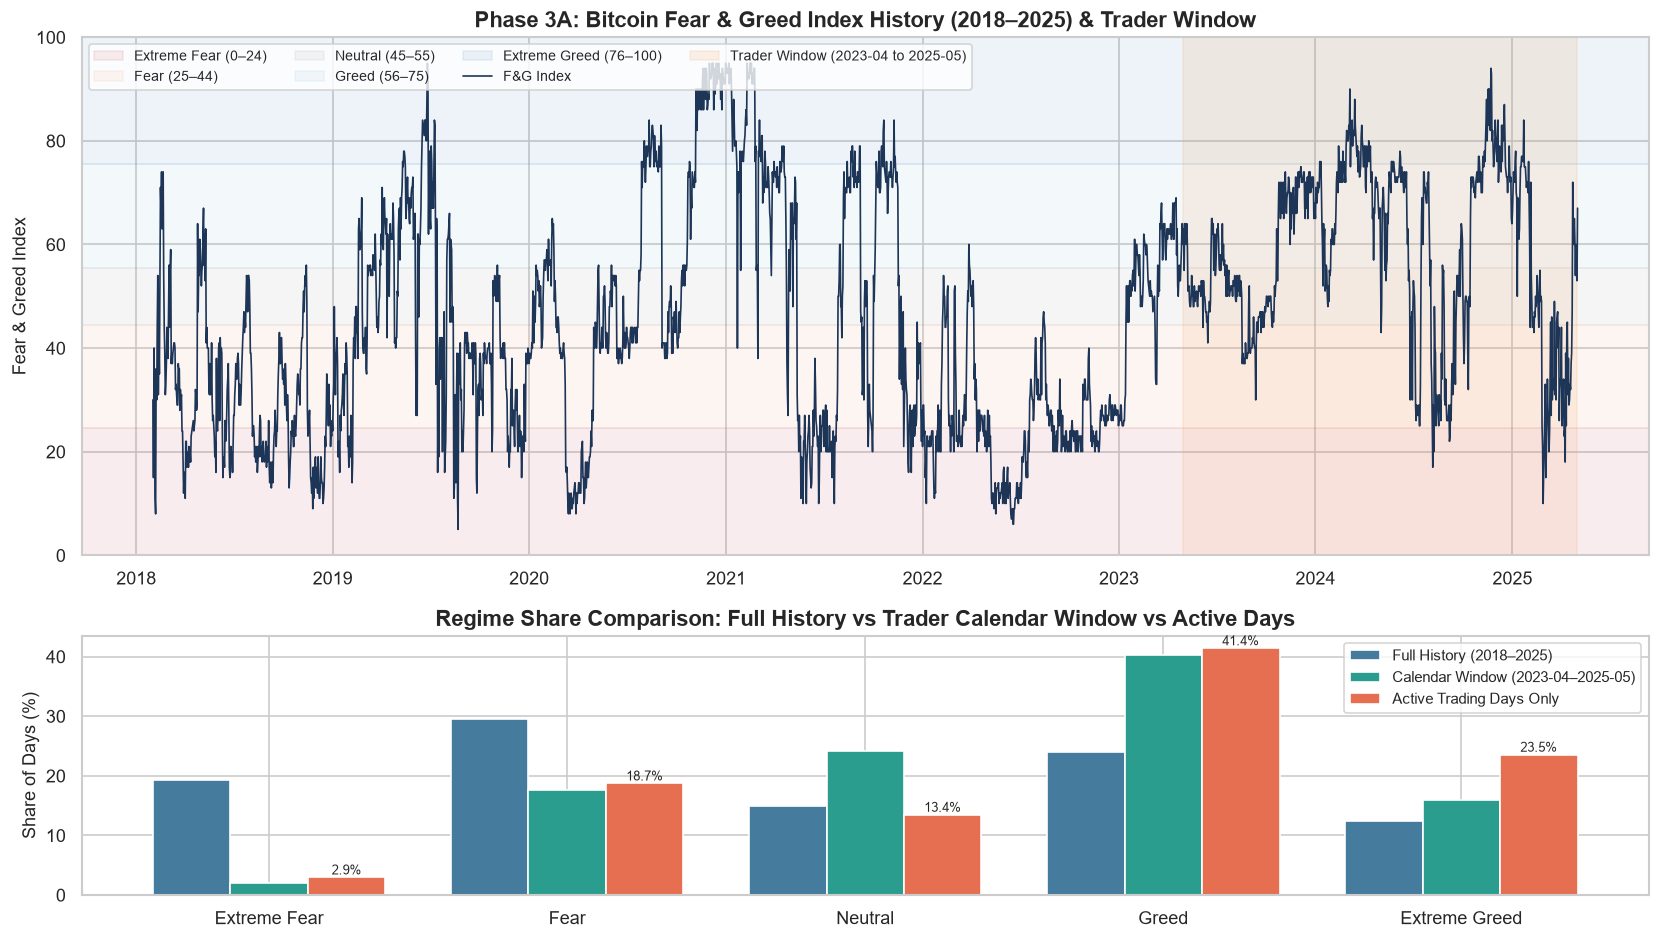

[Saved Image] outputs\02_eda_sentiment_transitions.png


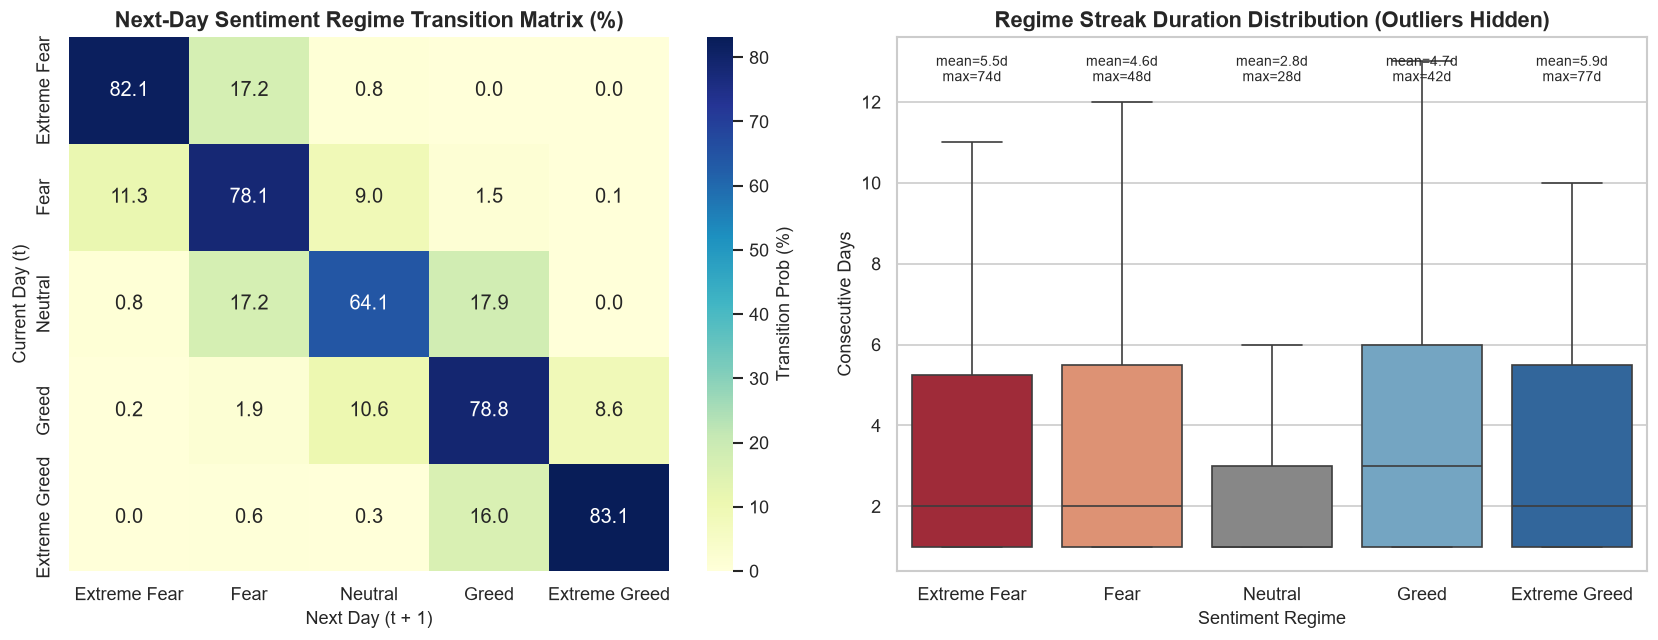

In [14]:
# 3A. Market Sentiment / Risk Regime Exploration
active_min_dt = merged_df["trade_date_dt"].min()
active_max_dt = merged_df["trade_date_dt"].max()
sent_window = clean_sent[
    (clean_sent["sentiment_date"] >= active_min_dt)
    & (clean_sent["sentiment_date"] <= active_max_dt)
].copy()

active_trade_dates = set(merged_df["trade_date_utc"].unique())
sent_traded_days = clean_sent[clean_sent["sentiment_date_str"].isin(active_trade_dates)].copy()

# Regime streak lengths across full 2018-2025 history
sent_sorted = clean_sent.sort_values("sentiment_date").reset_index(drop=True)
sent_sorted["streak_id"] = (sent_sorted["classification"] != sent_sorted["classification"].shift()).cumsum()
streaks = (
    sent_sorted.groupby(["streak_id", "classification"], as_index=False)
    .agg(streak_days=("sentiment_date", "count"))
)
streak_stats = (
    streaks.groupby("classification")["streak_days"]
    .agg(n_spells="count", mean_streak="mean", median_streak="median", max_streak="max")
    .reindex(SENTIMENT_ORDER)
)

# Summary table comparing Full History vs Active Trading Window vs Traded Days
sent_summary_rows = []
for cls in SENTIMENT_ORDER:
    n_full = int((clean_sent["classification"] == cls).sum())
    n_win = int((sent_window["classification"] == cls).sum())
    n_trd = int((sent_traded_days["classification"] == cls).sum())
    sent_summary_rows.append({
        "classification": cls,
        "full_days": n_full,
        "full_pct": round(100 * n_full / len(clean_sent), 2),
        "window_days": n_win,
        "window_pct": round(100 * n_win / len(sent_window), 2),
        "traded_days": n_trd,
        "traded_pct": round(100 * n_trd / len(sent_traded_days), 2),
        "mean_streak_days": round(float(streak_stats.loc[cls, "mean_streak"]), 2),
        "max_streak_days": int(streak_stats.loc[cls, "max_streak"]),
    })
sent_summary_df = pd.DataFrame(sent_summary_rows)
display(sent_summary_df)
export_csv(sent_summary_df, "03a_eda_sentiment_summary.csv")

# Plot 02_eda_sentiment_timeline.png
fig, axes = plt.subplots(2, 1, figsize=(14, 8), gridspec_kw={"height_ratios": [2.2, 1.1]})

ax = axes[0]
ax.axhspan(0, 24.5, color="#b2182b", alpha=0.08, label="Extreme Fear (0–24)")
ax.axhspan(24.5, 44.5, color="#ef8a62", alpha=0.08, label="Fear (25–44)")
ax.axhspan(44.5, 55.5, color="#878787", alpha=0.08, label="Neutral (45–55)")
ax.axhspan(55.5, 75.5, color="#67a9cf", alpha=0.08, label="Greed (56–75)")
ax.axhspan(75.5, 100, color="#2166ac", alpha=0.08, label="Extreme Greed (76–100)")
ax.plot(sent_sorted["sentiment_date"], sent_sorted["value"], color="#1d3557", linewidth=1.0, label="F&G Index")
ax.axvspan(active_min_dt, active_max_dt, color="#f4a261", alpha=0.14, label="Trader Window (2023-04 to 2025-05)")
ax.set_ylim(0, 100)
ax.set_ylabel("Fear & Greed Index")
ax.set_title("Phase 3A: Bitcoin Fear & Greed Index History (2018–2025) & Trader Window")
ax.legend(loc="upper left", ncol=4, fontsize=8.5)

x = np.arange(len(SENTIMENT_ORDER))
w = 0.26
axes[1].bar(x - w, sent_summary_df["full_pct"], width=w, label="Full History (2018–2025)", color="#457b9d")
axes[1].bar(x, sent_summary_df["window_pct"], width=w, label="Calendar Window (2023-04–2025-05)", color="#2a9d8f")
axes[1].bar(x + w, sent_summary_df["traded_pct"], width=w, label="Active Trading Days Only", color="#e76f51")
axes[1].set_xticks(x)
axes[1].set_xticklabels(SENTIMENT_ORDER)
axes[1].set_ylabel("Share of Days (%)")
axes[1].set_title("Regime Share Comparison: Full History vs Trader Calendar Window vs Active Days")
axes[1].legend(loc="upper right", fontsize=9)
for xi, v in zip(x + w, sent_summary_df["traded_pct"]):
    axes[1].text(xi, v + 0.5, f"{v:.1f}%", ha="center", fontsize=8)

plt.tight_layout()
save_fig(fig, "02_eda_sentiment_timeline.png")
plt.show()

# Plot 02_eda_sentiment_transitions.png (Next-Day Transition Matrix & Streak Durations)
sent_sorted["next_class"] = sent_sorted["classification"].shift(-1)
sent_sorted["day_diff"] = sent_sorted["sentiment_date"].diff().shift(-1).dt.days
trans_valid = sent_sorted[sent_sorted["day_diff"] == 1]
trans_mat = pd.crosstab(trans_valid["classification"], trans_valid["next_class"], normalize="index")
trans_mat = trans_mat.reindex(index=SENTIMENT_ORDER, columns=SENTIMENT_ORDER).fillna(0) * 100.0

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(
    trans_mat, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={"label": "Transition Prob (%)"}, ax=axes[0]
)
axes[0].set_title("Next-Day Sentiment Regime Transition Matrix (%)")
axes[0].set_xlabel("Next Day (t + 1)")
axes[0].set_ylabel("Current Day (t)")

streaks["classification"] = pd.Categorical(streaks["classification"], categories=SENTIMENT_ORDER, ordered=True)
sns.boxplot(
    data=streaks, x="classification", y="streak_days", palette=REGIME_COLORS, showfliers=False, ax=axes[1]
)
axes[1].set_title("Regime Streak Duration Distribution (Outliers Hidden)")
axes[1].set_xlabel("Sentiment Regime")
axes[1].set_ylabel("Consecutive Days")
for i, cls in enumerate(SENTIMENT_ORDER):
    mx = int(streak_stats.loc[cls, "max_streak"])
    mn = float(streak_stats.loc[cls, "mean_streak"])
    axes[1].text(i, axes[1].get_ylim()[1] * 0.92, f"mean={mn:.1f}d\nmax={mx}d", ha="center", fontsize=8.5)

plt.tight_layout()
save_fig(fig, "02_eda_sentiment_transitions.png")
plt.show()

,KPI,Value
0,Total Executed Trades,"211,224"
1,Unique Accounts / Coins,32 / 246
2,Active UTC Trading Days,476
3,Total Notional Volume (USD),"$1,191,187,442.46"
4,Trade Size USD (Median / Mean / P95),"$597.05 / $5,639.45 / $20,023.01"
5,Closing Trades (Closed PnL != 0),"104,408 (49.43%)"
6,Closing-Trade Win Rate,83.20%
7,Gross Profit / Gross Loss (USD),"$13,245,745.87 / -$2,948,786.93"
8,Profit Factor (Gross Profit / |Loss|),4.492
9,Net Closed PnL (Before Fees),"$10,296,958.94"


[Saved CSV] csv_files\03b_eda_global_kpis.csv | shape=(14, 2)
[Saved Image] outputs\03_eda_global_kpis_table.png
[Saved Image] outputs\03_eda_pnl_distribution.png


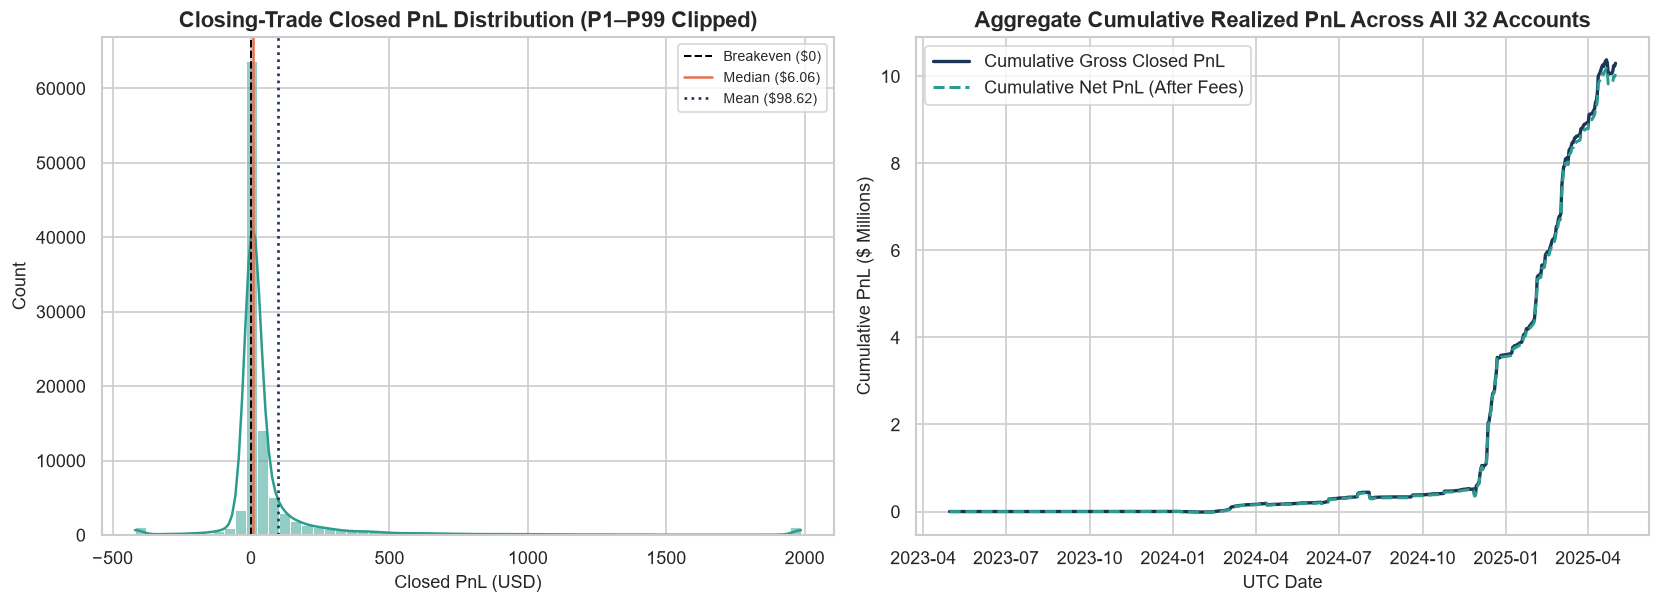

[Saved Image] outputs\03_eda_volume_distribution.png


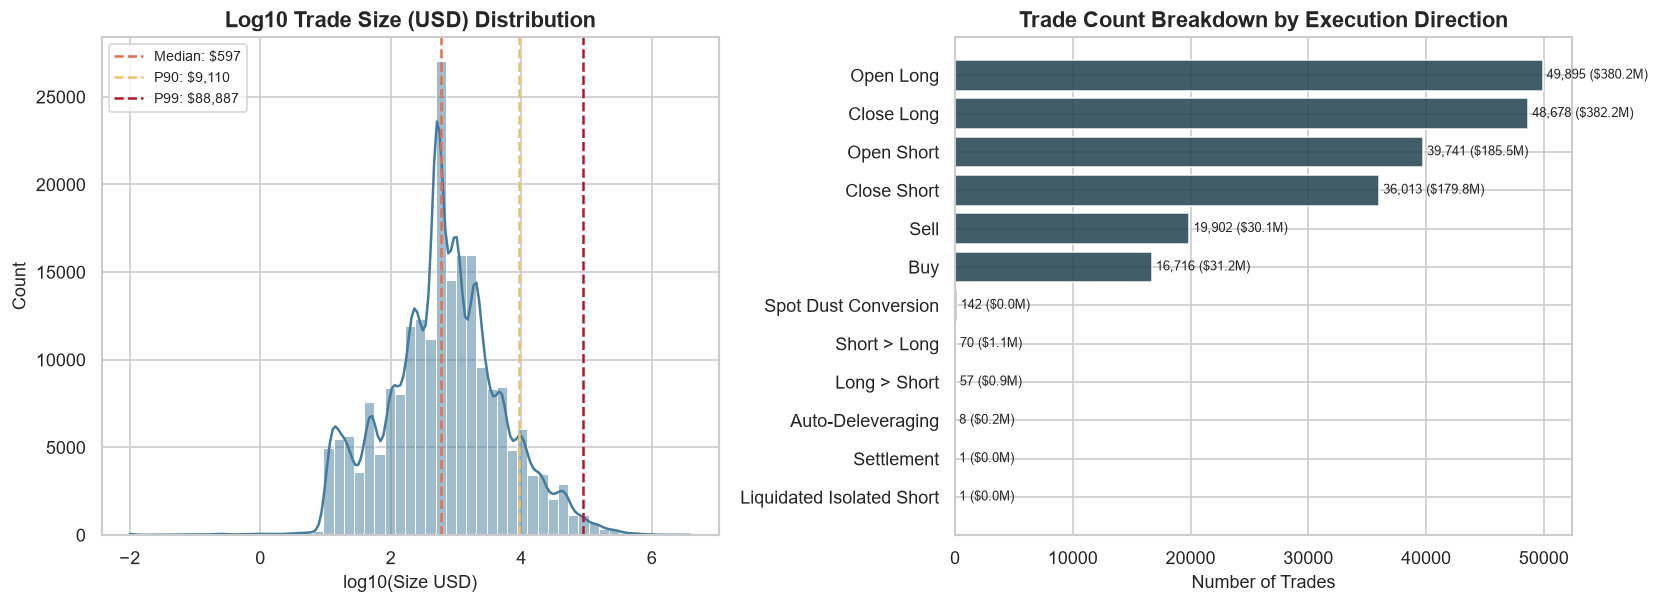

[Saved Image] outputs\03_eda_execution_and_side.png


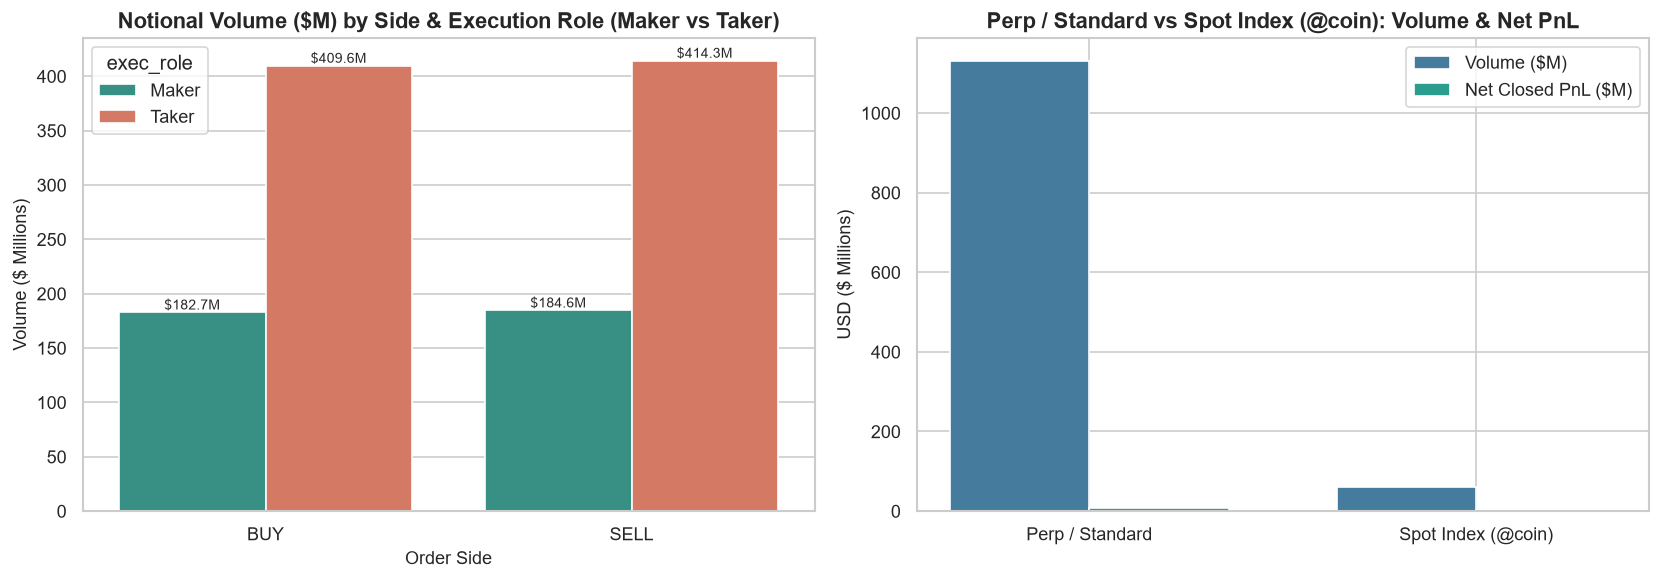

[Saved CSV] csv_files\03b_eda_top_coins.csv | shape=(246, 6)
[Saved Image] outputs\03_eda_symbol_breakdown.png


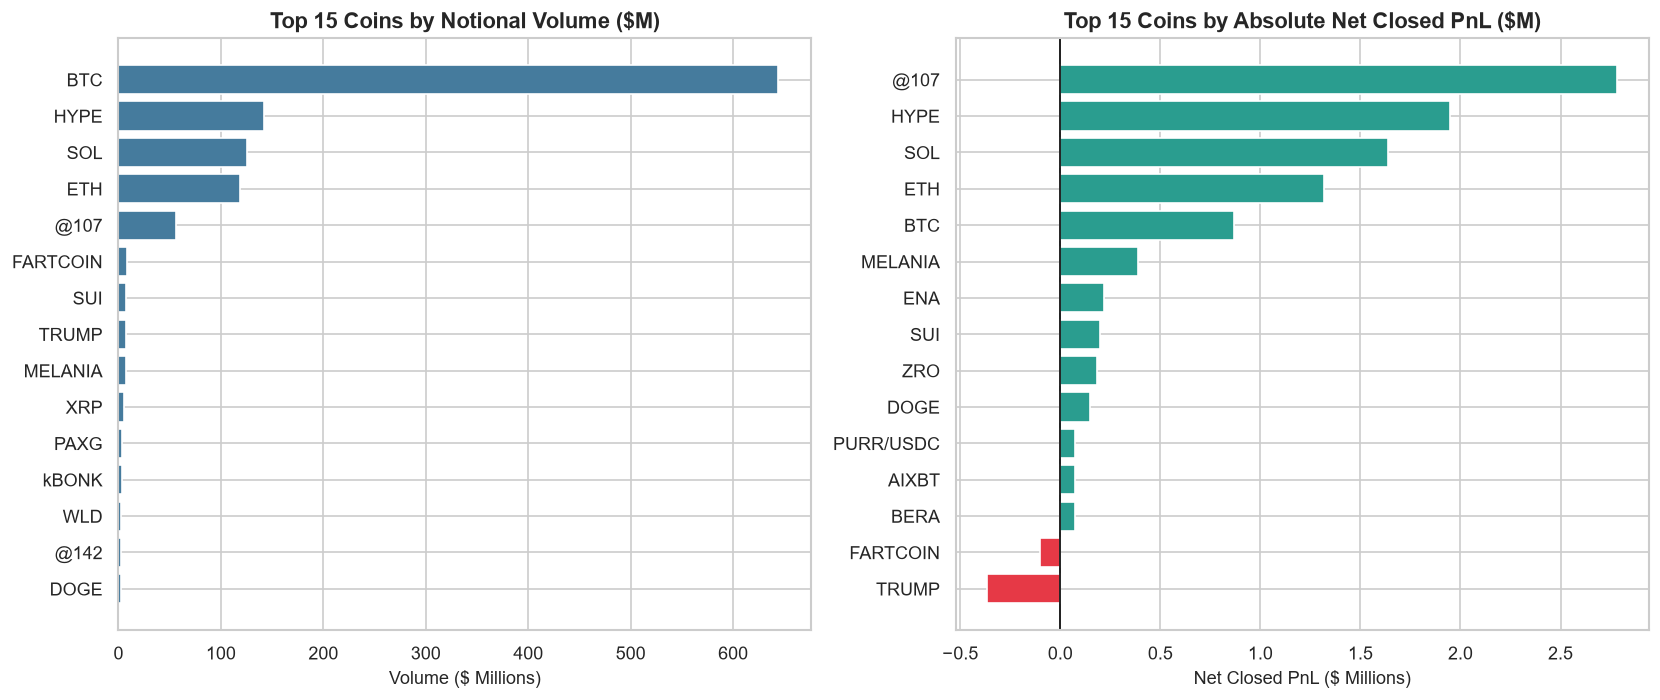

[Saved CSV] csv_files\03b_eda_account_overview.csv | shape=(32, 9)
[Saved Image] outputs\03_eda_trader_concentration.png


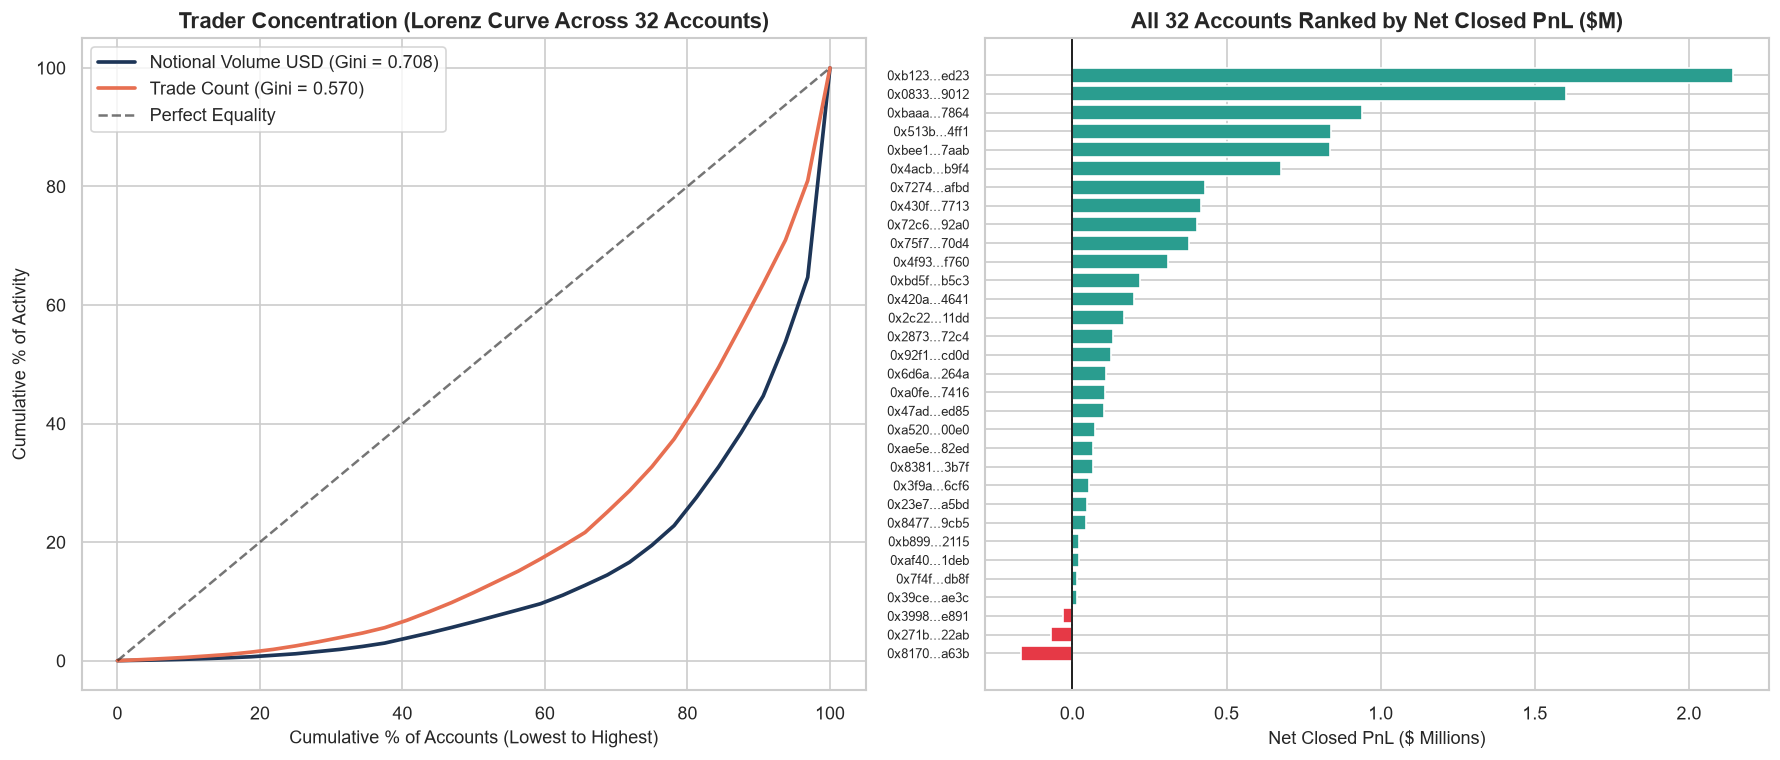

In [15]:
# 3B. Trader Activity, Volume, Concentration & Profitability Overview
closing = merged_df[merged_df["is_closing_trade"]].copy()
gross_profit = float(closing.loc[closing["closed_pnl"] > 0, "closed_pnl"].sum())
gross_loss = float(closing.loc[closing["closed_pnl"] < 0, "closed_pnl"].sum())
net_pnl = float(merged_df["closed_pnl"].sum())
total_fees = float(merged_df["fee"].sum())
profit_factor = gross_profit / abs(gross_loss) if gross_loss < 0 else np.nan
closing_win_rate = 100.0 * float((closing["closed_pnl"] > 0).mean())

global_kpis = pd.DataFrame([
    {"KPI": "Total Executed Trades", "Value": f"{len(merged_df):,}"},
    {"KPI": "Unique Accounts / Coins", "Value": f"{merged_df['account'].nunique():,} / {merged_df['coin'].nunique():,}"},
    {"KPI": "Active UTC Trading Days", "Value": f"{merged_df['trade_date_utc'].nunique():,}"},
    {"KPI": "Total Notional Volume (USD)", "Value": f"${merged_df['size_usd'].sum():,.2f}"},
    {"KPI": "Trade Size USD (Median / Mean / P95)", "Value": f"${merged_df['size_usd'].median():,.2f} / ${merged_df['size_usd'].mean():,.2f} / ${merged_df['size_usd'].quantile(0.95):,.2f}"},
    {"KPI": "Closing Trades (Closed PnL != 0)", "Value": f"{len(closing):,} ({100*len(closing)/len(merged_df):.2f}%)"},
    {"KPI": "Closing-Trade Win Rate", "Value": f"{closing_win_rate:.2f}%"},
    {"KPI": "Gross Profit / Gross Loss (USD)", "Value": f"${gross_profit:,.2f} / -${abs(gross_loss):,.2f}"},
    {"KPI": "Profit Factor (Gross Profit / |Loss|)", "Value": f"{profit_factor:.3f}"},
    {"KPI": "Net Closed PnL (Before Fees)", "Value": f"${net_pnl:,.2f}"},
    {"KPI": "Total Fees Paid", "Value": f"${total_fees:,.2f}"},
    {"KPI": "Net PnL After Fees", "Value": f"${net_pnl - total_fees:,.2f}"},
    {"KPI": "Taker Share / Maker Share", "Value": f"{100*merged_df['crossed'].mean():.2f}% / {100*merged_df['is_maker'].mean():.2f}%"},
    {"KPI": "Perp-Standard / Spot-Index (@coin)", "Value": f"{100*(~merged_df['is_spot_index']).mean():.2f}% / {100*merged_df['is_spot_index'].mean():.2f}%"},
])

display(global_kpis)
export_csv(global_kpis, "03b_eda_global_kpis.csv")
save_table_image(
    global_kpis,
    "03_eda_global_kpis_table.png",
    title="Phase 3B: Global Trader Activity & Profitability KPIs",
    col_width=5.2,
)

# 1) PnL Distribution & Cumulative PnL Curve -> 03_eda_pnl_distribution.png
p01, p99 = closing["closed_pnl"].quantile([0.01, 0.99])
closing_clipped = closing["closed_pnl"].clip(p01, p99)

daily_pnl = (
    merged_df.groupby("trade_date_dt", as_index=False)
    .agg(net_pnl=("closed_pnl", "sum"), fees=("fee", "sum"))
    .sort_values("trade_date_dt")
)
daily_pnl["cum_pnl"] = daily_pnl["net_pnl"].cumsum()
daily_pnl["cum_pnl_after_fees"] = (daily_pnl["net_pnl"] - daily_pnl["fees"]).cumsum()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
sns.histplot(closing_clipped, bins=60, kde=True, color="#2a9d8f", ax=axes[0])
axes[0].axvline(0, color="black", linestyle="--", linewidth=1.2, label="Breakeven ($0)")
axes[0].axvline(closing["closed_pnl"].median(), color="#e76f51", linestyle="-", linewidth=1.5, label=f"Median (${closing['closed_pnl'].median():,.2f})")
axes[0].axvline(closing["closed_pnl"].mean(), color="#1d3557", linestyle=":", linewidth=1.6, label=f"Mean (${closing['closed_pnl'].mean():,.2f})")
axes[0].set_title("Closing-Trade Closed PnL Distribution (P1–P99 Clipped)")
axes[0].set_xlabel("Closed PnL (USD)")
axes[0].legend(fontsize=8.5)

axes[1].plot(daily_pnl["trade_date_dt"], daily_pnl["cum_pnl"] / 1e6, label="Cumulative Gross Closed PnL", color="#1d3557", linewidth=2.0)
axes[1].plot(daily_pnl["trade_date_dt"], daily_pnl["cum_pnl_after_fees"] / 1e6, label="Cumulative Net PnL (After Fees)", color="#2a9d8f", linewidth=1.8, linestyle="--")
axes[1].set_title("Aggregate Cumulative Realized PnL Across All 32 Accounts")
axes[1].set_xlabel("UTC Date")
axes[1].set_ylabel("Cumulative PnL ($ Millions)")
axes[1].legend()

plt.tight_layout()
save_fig(fig, "03_eda_pnl_distribution.png")
plt.show()

# 2) Trade Size Log Distribution & Direction Breakdown -> 03_eda_volume_distribution.png
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
log_size = np.log10(merged_df["size_usd"].clip(lower=1e-2))
sns.histplot(log_size, bins=55, kde=True, color="#457b9d", ax=axes[0])
for label, q, c in [("Median", 0.50, "#e76f51"), ("P90", 0.90, "#e9c46a"), ("P99", 0.99, "#b2182b")]:
    qv = merged_df["size_usd"].quantile(q)
    axes[0].axvline(np.log10(max(qv, 1e-2)), color=c, linestyle="--", linewidth=1.5, label=f"{label}: ${qv:,.0f}")
axes[0].set_title("Log10 Trade Size (USD) Distribution")
axes[0].set_xlabel("log10(Size USD)")
axes[0].legend(fontsize=8.5)

dir_summary = (
    merged_df.groupby("direction", as_index=False)
    .agg(trades=("account", "size"), volume_usd=("size_usd", "sum"))
    .sort_values("trades", ascending=True)
)
axes[1].barh(dir_summary["direction"], dir_summary["trades"], color="#264653", alpha=0.88)
axes[1].set_title("Trade Count Breakdown by Execution Direction")
axes[1].set_xlabel("Number of Trades")
for idx, (tr, vol) in enumerate(zip(dir_summary["trades"], dir_summary["volume_usd"])):
    axes[1].text(tr, idx, f" {tr:,} (${vol/1e6:,.1f}M)", va="center", fontsize=8)

plt.tight_layout()
save_fig(fig, "03_eda_volume_distribution.png")
plt.show()

# 3) Execution Role (Maker/Taker), Side (BUY/SELL) & Market Type -> 03_eda_execution_and_side.png
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

side_exec = (
    merged_df.assign(exec_role=np.where(merged_df["crossed"], "Taker", "Maker"))
    .groupby(["side", "exec_role"], as_index=False)
    .agg(trades=("account", "size"), volume_m=("size_usd", lambda s: s.sum() / 1e6))
)
sns.barplot(data=side_exec, x="side", y="volume_m", hue="exec_role", palette=["#2a9d8f", "#e76f51"], ax=axes[0])
axes[0].set_title("Notional Volume ($M) by Side & Execution Role (Maker vs Taker)")
axes[0].set_ylabel("Volume ($ Millions)")
axes[0].set_xlabel("Order Side")
for p in axes[0].patches:
    h = p.get_height()
    if h > 0:
        axes[0].text(p.get_x() + p.get_width() / 2, h, f"${h:,.1f}M", ha="center", va="bottom", fontsize=8.5)

mkt_comp = (
    merged_df.assign(market_type=np.where(merged_df["is_spot_index"], "Spot Index (@coin)", "Perp / Standard"))
    .groupby("market_type", as_index=False)
    .agg(
        trades=("account", "size"),
        volume_m=("size_usd", lambda s: s.sum() / 1e6),
        net_pnl_m=("closed_pnl", lambda s: s.sum() / 1e6),
    )
)
x_m = np.arange(len(mkt_comp))
axes[1].bar(x_m - 0.18, mkt_comp["volume_m"], width=0.36, label="Volume ($M)", color="#457b9d")
axes[1].bar(x_m + 0.18, mkt_comp["net_pnl_m"], width=0.36, label="Net Closed PnL ($M)", color="#2a9d8f")
axes[1].set_xticks(x_m)
axes[1].set_xticklabels(mkt_comp["market_type"])
axes[1].set_title("Perp / Standard vs Spot Index (@coin): Volume & Net PnL")
axes[1].set_ylabel("USD ($ Millions)")
axes[1].legend()

plt.tight_layout()
save_fig(fig, "03_eda_execution_and_side.png")
plt.show()

# 4) Top Coins Breakdown -> 03_eda_symbol_breakdown.png
coin_stats = (
    merged_df.groupby("coin", as_index=False)
    .agg(
        trades=("account", "size"),
        accounts=("account", "nunique"),
        volume_usd=("size_usd", "sum"),
        net_pnl=("closed_pnl", "sum"),
        fees=("fee", "sum"),
    )
    .sort_values("volume_usd", ascending=False)
)
export_csv(coin_stats, "03b_eda_top_coins.csv")

top15_vol = coin_stats.head(15).sort_values("volume_usd", ascending=True)
top15_pnl = coin_stats.reindex(coin_stats["net_pnl"].abs().sort_values(ascending=False).index).head(15).sort_values("net_pnl", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(top15_vol["coin"], top15_vol["volume_usd"] / 1e6, color="#457b9d")
axes[0].set_title("Top 15 Coins by Notional Volume ($M)")
axes[0].set_xlabel("Volume ($ Millions)")

pnl_colors = ["#2a9d8f" if v >= 0 else "#e63946" for v in top15_pnl["net_pnl"]]
axes[1].barh(top15_pnl["coin"], top15_pnl["net_pnl"] / 1e6, color=pnl_colors)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("Top 15 Coins by Absolute Net Closed PnL ($M)")
axes[1].set_xlabel("Net Closed PnL ($ Millions)")

plt.tight_layout()
save_fig(fig, "03_eda_symbol_breakdown.png")
plt.show()

# 5) Account Concentration (Lorenz Curve & Account PnL Ranking) -> 03_eda_trader_concentration.png
acct_stats = (
    merged_df.groupby("account", as_index=False)
    .agg(
        trades=("coin", "size"),
        active_days=("trade_date_utc", "nunique"),
        volume_usd=("size_usd", "sum"),
        net_pnl=("closed_pnl", "sum"),
        fees=("fee", "sum"),
        taker_pct=("crossed", lambda s: 100.0 * s.mean()),
    )
    .sort_values("net_pnl", ascending=False)
    .reset_index(drop=True)
)
acct_stats["net_pnl_after_fees"] = acct_stats["net_pnl"] - acct_stats["fees"]
acct_stats["short_acct"] = acct_stats["account"].str[:6] + "..." + acct_stats["account"].str[-4:]
export_csv(acct_stats, "03b_eda_account_overview.csv")


def gini_coeff(arr: np.ndarray) -> float:
    s = np.sort(np.asarray(arr, dtype=float))
    n = len(s)
    if n == 0 or s.sum() == 0:
        return 0.0
    idx = np.arange(1, n + 1)
    return float((2 * np.sum(idx * s)) / (n * np.sum(s)) - (n + 1) / n)


fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

for col, label, color in [
    ("volume_usd", "Notional Volume USD", "#1d3557"),
    ("trades", "Trade Count", "#e76f51"),
]:
    vals = np.sort(acct_stats[col].values)
    cum_share = np.insert(np.cumsum(vals) / vals.sum(), 0, 0.0) * 100
    pop_share = np.linspace(0, 100, len(cum_share))
    g = gini_coeff(vals)
    axes[0].plot(pop_share, cum_share, linewidth=2.2, color=color, label=f"{label} (Gini = {g:.3f})")

axes[0].plot([0, 100], [0, 100], "k--", alpha=0.6, label="Perfect Equality")
axes[0].set_title("Trader Concentration (Lorenz Curve Across 32 Accounts)")
axes[0].set_xlabel("Cumulative % of Accounts (Lowest to Highest)")
axes[0].set_ylabel("Cumulative % of Activity")
axes[0].legend(loc="upper left")

acct_plot = acct_stats.sort_values("net_pnl", ascending=True)
bar_c = ["#2a9d8f" if v >= 0 else "#e63946" for v in acct_plot["net_pnl"]]
axes[1].barh(acct_plot["short_acct"], acct_plot["net_pnl"] / 1e6, color=bar_c)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("All 32 Accounts Ranked by Net Closed PnL ($M)")
axes[1].set_xlabel("Net Closed PnL ($ Millions)")
axes[1].tick_params(axis="y", labelsize=8)

plt.tight_layout()
save_fig(fig, "03_eda_trader_concentration.png")
plt.show()

,sentiment_class,active_days,total_trades,trades_per_day,avg_daily_accounts,total_volume_m,volume_per_day_m,median_size_usd,mean_size_usd,p90_size_usd,...,win_rate_pct,mean_closing_pnl,median_closing_pnl,net_pnl_usd,pnl_per_day_usd,profit_factor,taker_pct,buy_vol_pct,open_long_share_pct,spot_pct
0,Extreme Fear,14,21303,1521.64,11.00,116.43,8.316,789.07,5465.26,9076.83,...,78.45,94.50,8.54,1072333.98,76595.28,2.846,59.47,47.45,65.28,7.71
1,Fear,89,61510,691.12,7.13,486.35,5.465,699.25,7906.82,11015.35,...,86.72,96.12,5.66,2868016.10,32224.90,5.482,59.83,49.08,59.62,10.85
2,Neutral,64,39563,618.17,5.83,191.74,2.996,556.81,4846.49,7289.84,...,80.07,72.69,4.10,1302024.78,20344.14,4.885,59.50,47.00,65.69,12.09
3,Greed,197,48668,247.05,3.34,269.51,1.368,555.00,5537.64,9956.41,...,78.50,100.08,5.74,2439462.99,12383.06,3.197,62.22,53.95,41.59,20.67
4,Extreme Greed,112,40180,358.75,4.68,127.16,1.135,500.20,3164.88,5780.51,...,88.91,124.92,8.46,2615121.09,23349.30,10.261,62.50,49.45,47.17,26.94


[Saved CSV] csv_files\03c_eda_regime_summary.csv | shape=(5, 21)
[Saved Image] outputs\04_eda_regime_summary_table.png
[Saved Image] outputs\04_eda_activity_by_regime.png


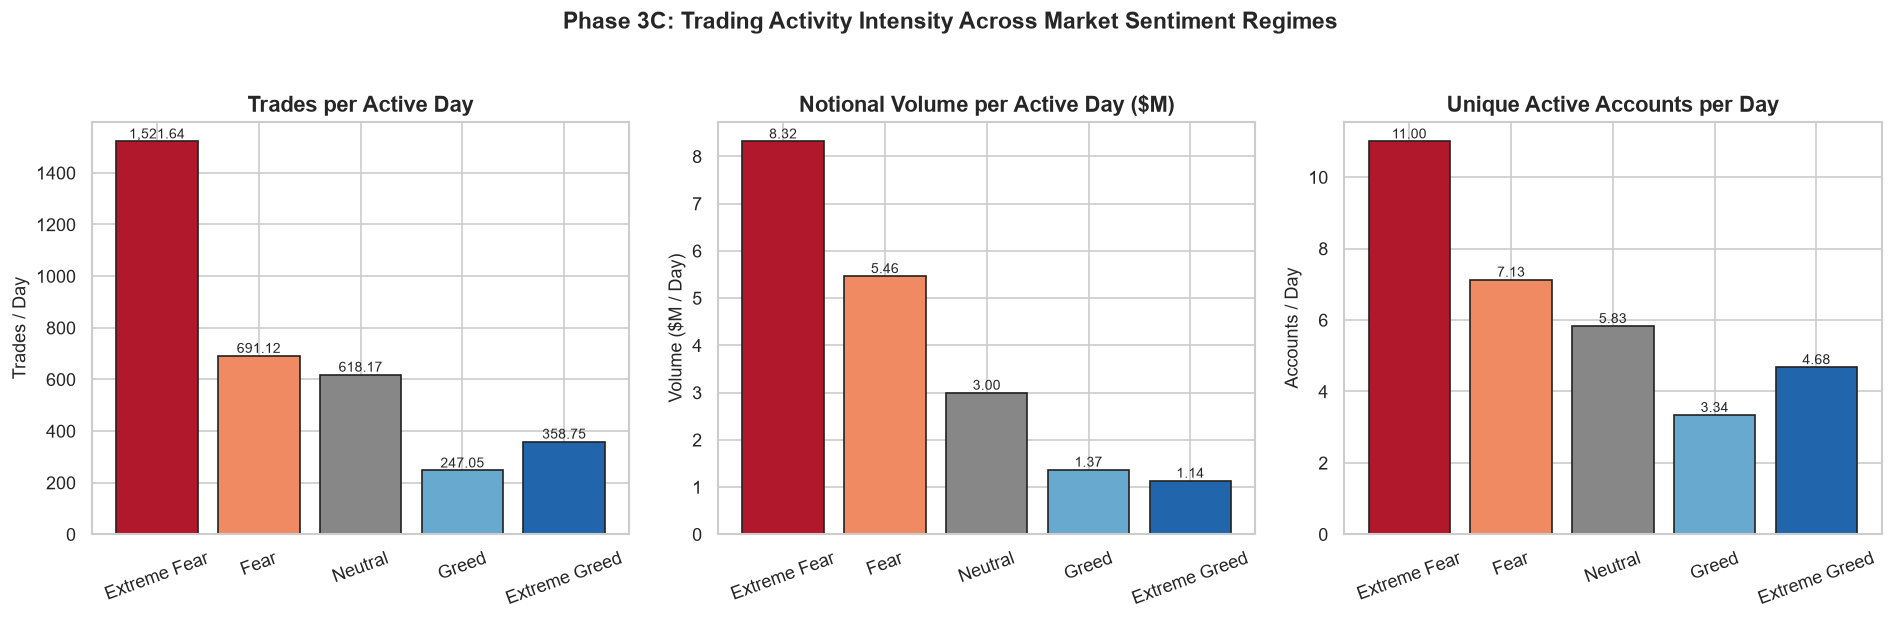

[Saved Image] outputs\04_eda_pnl_by_regime.png


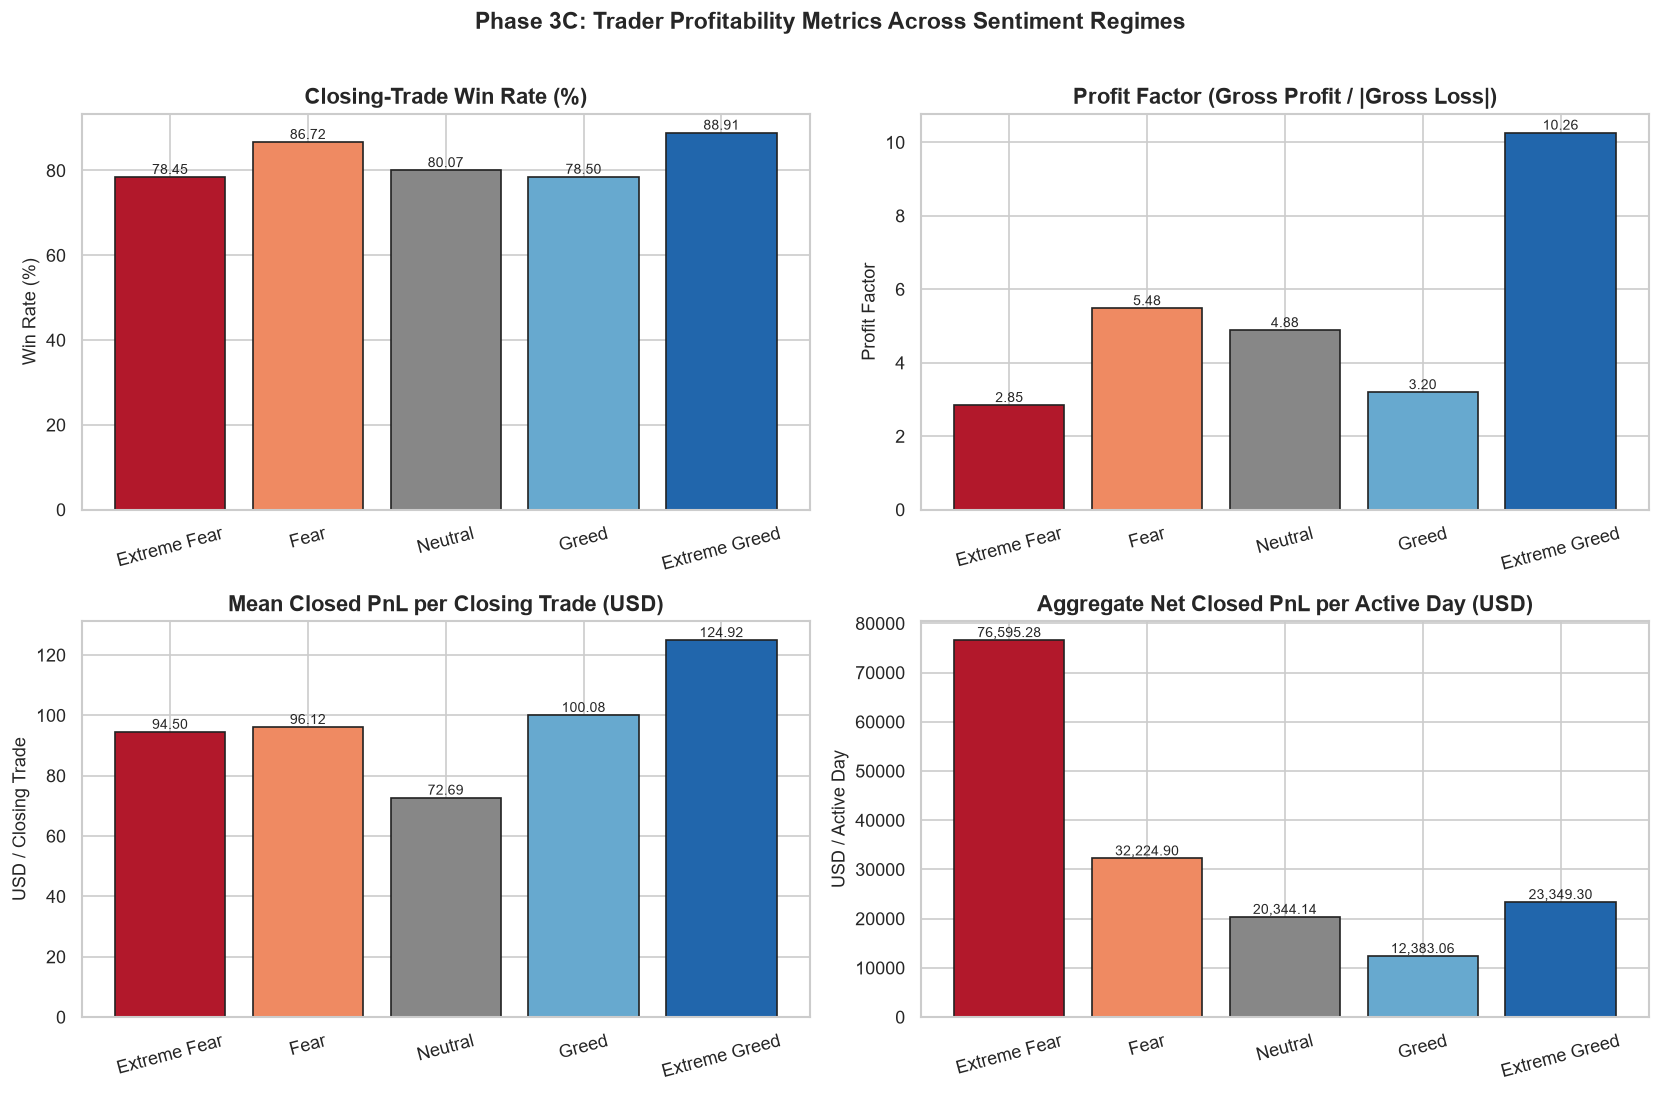

[Saved Image] outputs\04_eda_risk_and_bias_by_regime.png


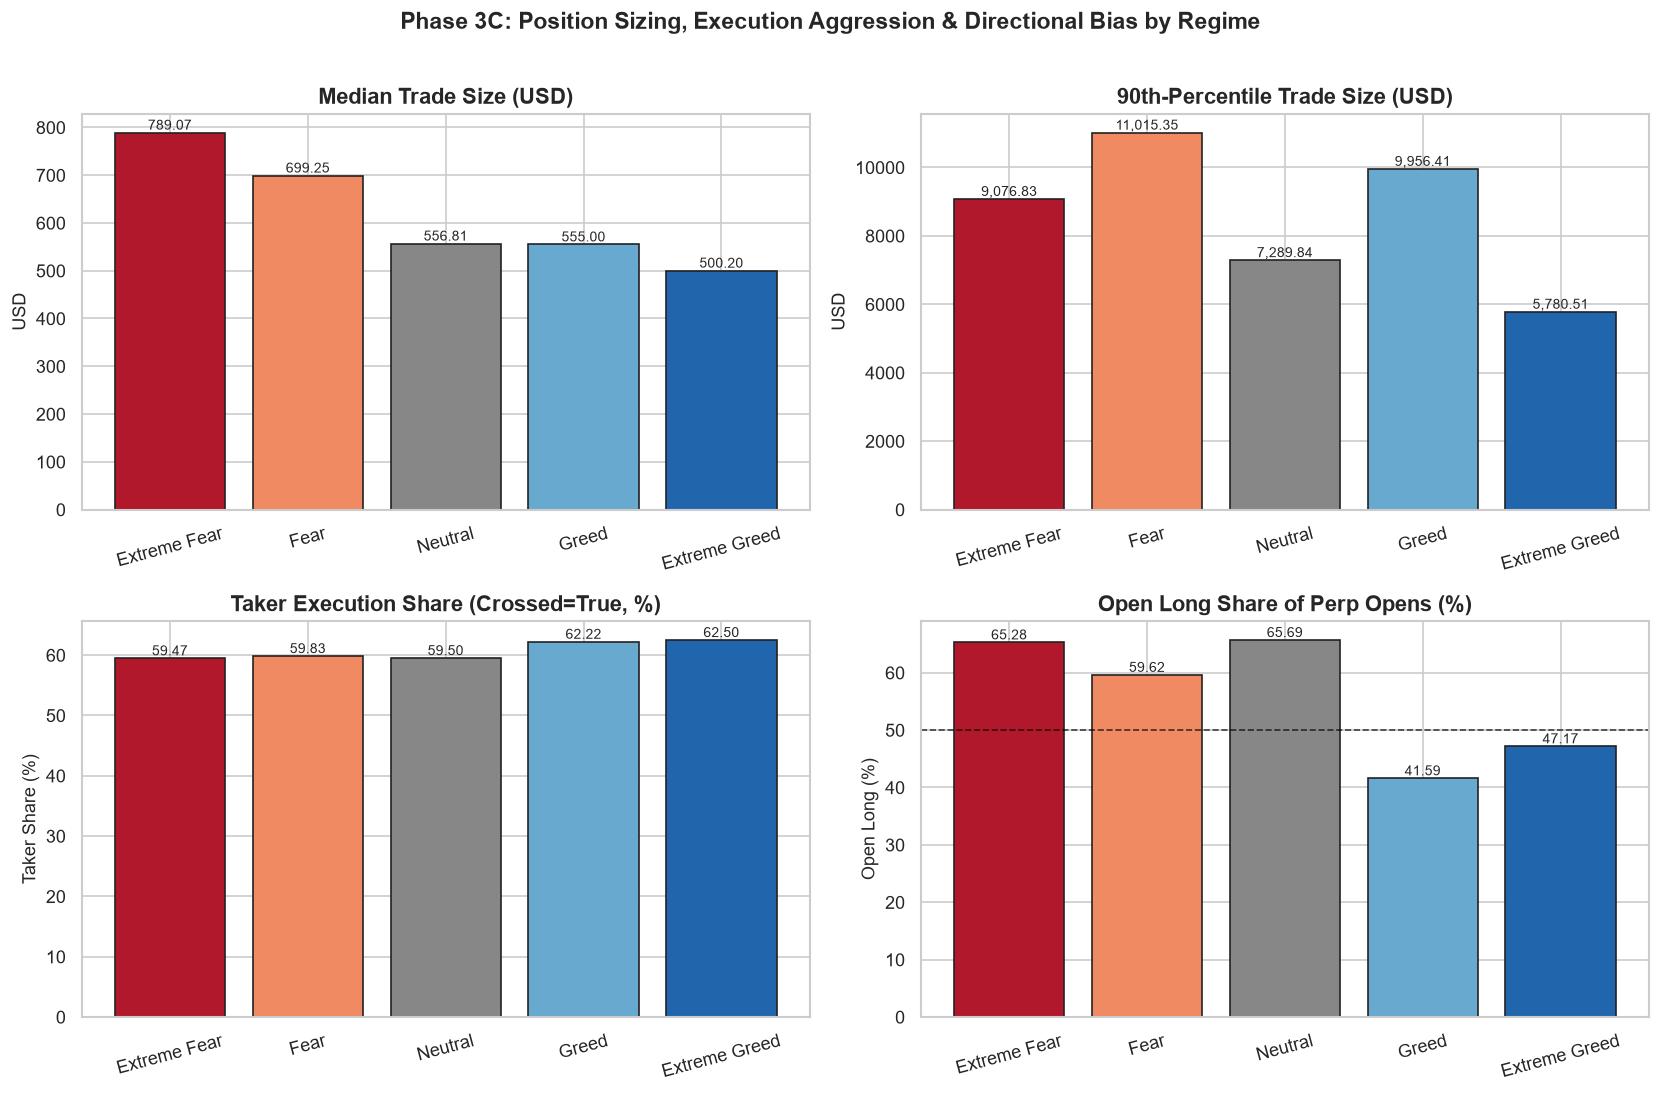

[Saved Image] outputs\04_eda_temporal_heatmap_by_regime.png


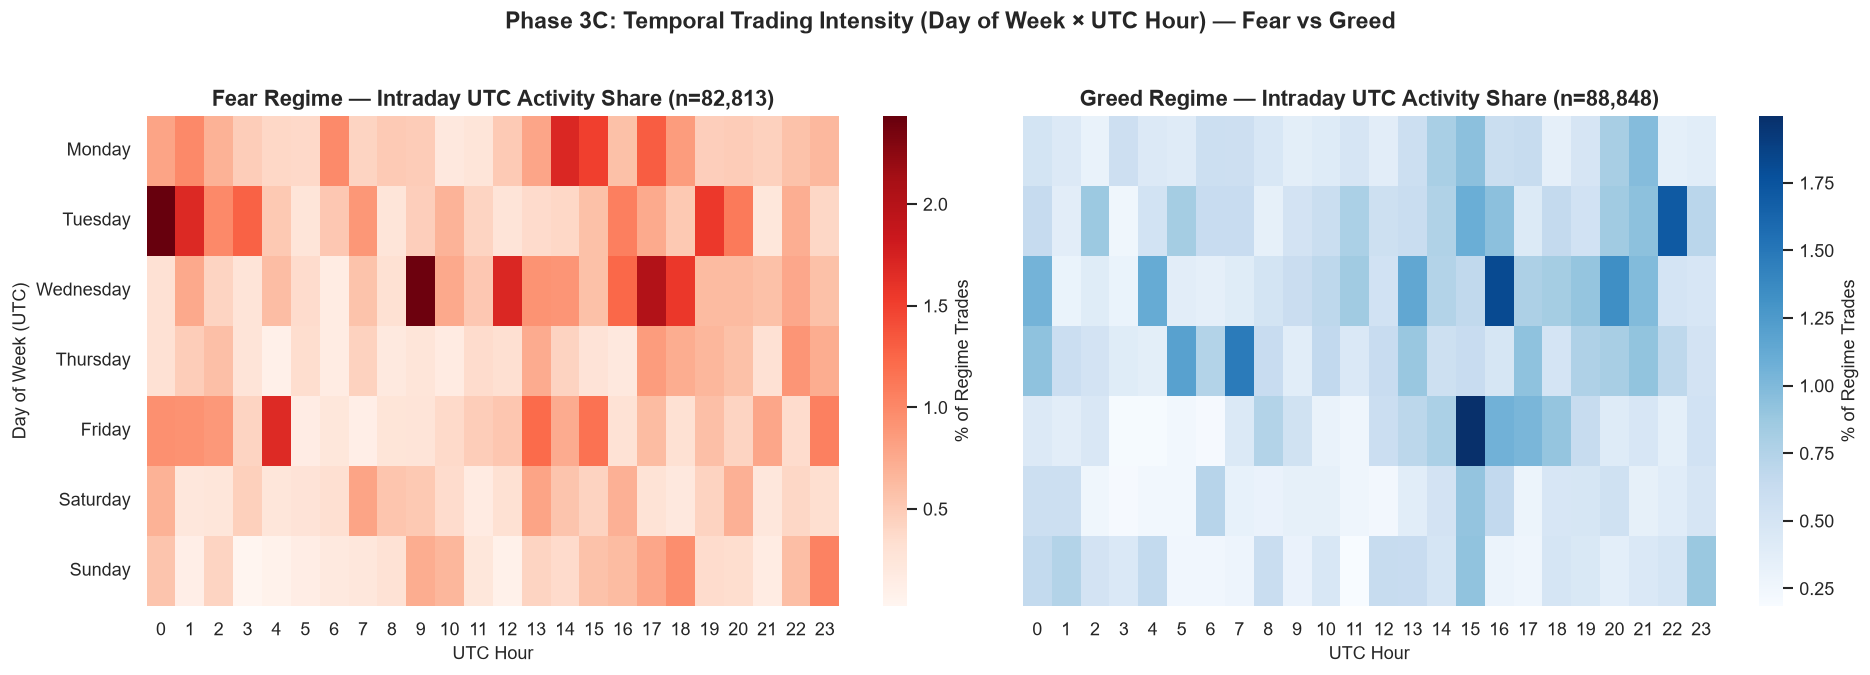

In [16]:
# 3C. Trader Behavior & Performance Across Market Sentiment Regimes
regime_rows = []
for reg in SENTIMENT_ORDER:
    sub = merged_df[merged_df["sentiment_class"] == reg]
    sub_close = sub[sub["is_closing_trade"]]
    n_days = max(int(sub["trade_date_utc"].nunique()), 1)

    gp = float(sub_close.loc[sub_close["closed_pnl"] > 0, "closed_pnl"].sum())
    gl = float(sub_close.loc[sub_close["closed_pnl"] < 0, "closed_pnl"].sum())
    pf = gp / abs(gl) if gl < 0 else np.nan
    wr = 100.0 * float((sub_close["closed_pnl"] > 0).mean()) if len(sub_close) else np.nan

    n_open_long = int((sub["direction"] == "Open Long").sum())
    n_open_short = int((sub["direction"] == "Open Short").sum())
    open_long_pct = 100.0 * n_open_long / max(n_open_long + n_open_short, 1)

    buy_vol = float(sub.loc[sub["side"] == "BUY", "size_usd"].sum())
    tot_vol = float(sub["size_usd"].sum())
    daily_accts = float(sub.groupby("trade_date_utc")["account"].nunique().mean())

    regime_rows.append({
        "sentiment_class": reg,
        "active_days": n_days,
        "total_trades": len(sub),
        "trades_per_day": round(len(sub) / n_days, 2),
        "avg_daily_accounts": round(daily_accts, 2),
        "total_volume_m": round(tot_vol / 1e6, 2),
        "volume_per_day_m": round((tot_vol / n_days) / 1e6, 3),
        "median_size_usd": round(float(sub["size_usd"].median()), 2),
        "mean_size_usd": round(float(sub["size_usd"].mean()), 2),
        "p90_size_usd": round(float(sub["size_usd"].quantile(0.90)), 2),
        "closing_trades": len(sub_close),
        "win_rate_pct": round(wr, 2),
        "mean_closing_pnl": round(float(sub_close["closed_pnl"].mean()), 2),
        "median_closing_pnl": round(float(sub_close["closed_pnl"].median()), 2),
        "net_pnl_usd": round(float(sub["closed_pnl"].sum()), 2),
        "pnl_per_day_usd": round(float(sub["closed_pnl"].sum()) / n_days, 2),
        "profit_factor": round(pf, 3),
        "taker_pct": round(100.0 * float(sub["crossed"].mean()), 2),
        "buy_vol_pct": round(100.0 * buy_vol / max(tot_vol, 1e-9), 2),
        "open_long_share_pct": round(open_long_pct, 2),
        "spot_pct": round(100.0 * float(sub["is_spot_index"].mean()), 2),
    })

regime_summary = pd.DataFrame(regime_rows)
display(regime_summary)
export_csv(regime_summary, "03c_eda_regime_summary.csv")

compact_regime_tbl = regime_summary[[
    "sentiment_class", "active_days", "trades_per_day", "volume_per_day_m",
    "median_size_usd", "win_rate_pct", "profit_factor", "pnl_per_day_usd",
    "taker_pct", "open_long_share_pct",
]].copy()
save_table_image(
    compact_regime_tbl,
    "04_eda_regime_summary_table.png",
    title="Phase 3C: Daily-Normalized Trader Behavior & Profitability by Sentiment Regime",
    col_width=2.3,
)

# 1) Activity by Regime -> 04_eda_activity_by_regime.png
palette_list = [REGIME_COLORS[c] for c in SENTIMENT_ORDER]
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, col, title, ylabel in [
    (axes[0], "trades_per_day", "Trades per Active Day", "Trades / Day"),
    (axes[1], "volume_per_day_m", "Notional Volume per Active Day ($M)", "Volume ($M / Day)"),
    (axes[2], "avg_daily_accounts", "Unique Active Accounts per Day", "Accounts / Day"),
]:
    bars = ax.bar(regime_summary["sentiment_class"], regime_summary[col], color=palette_list, edgecolor="#222")
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=20)
    for b, v in zip(bars, regime_summary[col]):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,.2f}", ha="center", va="bottom", fontsize=8.5)

fig.suptitle("Phase 3C: Trading Activity Intensity Across Market Sentiment Regimes", fontsize=14, fontweight="bold", y=1.03)
plt.tight_layout()
save_fig(fig, "04_eda_activity_by_regime.png")
plt.show()

# 2) Profitability by Regime -> 04_eda_pnl_by_regime.png
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
pnl_panels = [
    (axes[0, 0], "win_rate_pct", "Closing-Trade Win Rate (%)", "Win Rate (%)"),
    (axes[0, 1], "profit_factor", "Profit Factor (Gross Profit / |Gross Loss|)", "Profit Factor"),
    (axes[1, 0], "mean_closing_pnl", "Mean Closed PnL per Closing Trade (USD)", "USD / Closing Trade"),
    (axes[1, 1], "pnl_per_day_usd", "Aggregate Net Closed PnL per Active Day (USD)", "USD / Active Day"),
]
for ax, col, title, ylabel in pnl_panels:
    bars = ax.bar(regime_summary["sentiment_class"], regime_summary[col], color=palette_list, edgecolor="#222")
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=15)
    for b, v in zip(bars, regime_summary[col]):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,.2f}", ha="center", va="bottom", fontsize=8.5)

fig.suptitle("Phase 3C: Trader Profitability Metrics Across Sentiment Regimes", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
save_fig(fig, "04_eda_pnl_by_regime.png")
plt.show()

# 3) Risk, Sizing, Taker Aggression & Long/Short Bias -> 04_eda_risk_and_bias_by_regime.png
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
bias_panels = [
    (axes[0, 0], "median_size_usd", "Median Trade Size (USD)", "USD"),
    (axes[0, 1], "p90_size_usd", "90th-Percentile Trade Size (USD)", "USD"),
    (axes[1, 0], "taker_pct", "Taker Execution Share (Crossed=True, %)", "Taker Share (%)"),
    (axes[1, 1], "open_long_share_pct", "Open Long Share of Perp Opens (%)", "Open Long (%)"),
]
for ax, col, title, ylabel in bias_panels:
    bars = ax.bar(regime_summary["sentiment_class"], regime_summary[col], color=palette_list, edgecolor="#222")
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=15)
    if col == "open_long_share_pct":
        ax.axhline(50, color="black", linestyle="--", linewidth=1, alpha=0.7)
    for b, v in zip(bars, regime_summary[col]):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,.2f}", ha="center", va="bottom", fontsize=8.5)

fig.suptitle("Phase 3C: Position Sizing, Execution Aggression & Directional Bias by Regime", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
save_fig(fig, "04_eda_risk_and_bias_by_regime.png")
plt.show()

# 4) Day-of-Week x UTC Hour Activity Heatmap (Fear vs Greed) -> 04_eda_temporal_heatmap_by_regime.png
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)

for ax, coarse_reg, cmap in [(axes[0], "Fear", "Reds"), (axes[1], "Greed", "Blues")]:
    sub_h = merged_df[merged_df["regime_coarse"] == coarse_reg]
    piv = pd.crosstab(sub_h["day_of_week_utc"], sub_h["hour_utc"]).reindex(index=dow_order, columns=range(24)).fillna(0)
    piv_pct = 100.0 * piv / max(piv.values.sum(), 1)
    sns.heatmap(piv_pct, cmap=cmap, cbar_kws={"label": "% of Regime Trades"}, ax=ax)
    ax.set_title(f"{coarse_reg} Regime — Intraday UTC Activity Share (n={len(sub_h):,})")
    ax.set_xlabel("UTC Hour")
    ax.set_ylabel("Day of Week (UTC)" if coarse_reg == "Fear" else "")

fig.suptitle("Phase 3C: Temporal Trading Intensity (Day of Week × UTC Hour) — Fear vs Greed", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
save_fig(fig, "04_eda_temporal_heatmap_by_regime.png")
plt.show()

,metric,spearman_vs_sentiment,pearson_vs_sentiment
0,sentiment_value,1.0000,1.0000
1,sentiment_delta_1d,0.1646,0.1795
2,trade_count,-0.0501,-0.2507
3,active_accounts,-0.1661,-0.2860
4,total_volume_usd,-0.0707,-0.2736
5,median_size_usd,0.0088,0.0426
6,net_pnl,0.0150,-0.0926
7,win_rate_pct,0.0722,0.0434
8,taker_pct,-0.0994,-0.0565
9,buy_vol_pct,-0.0206,0.0145


[Saved CSV] csv_files\03d_eda_correlations.csv | shape=(11, 3)
[Saved Image] outputs\05_eda_correlation_heatmap.png


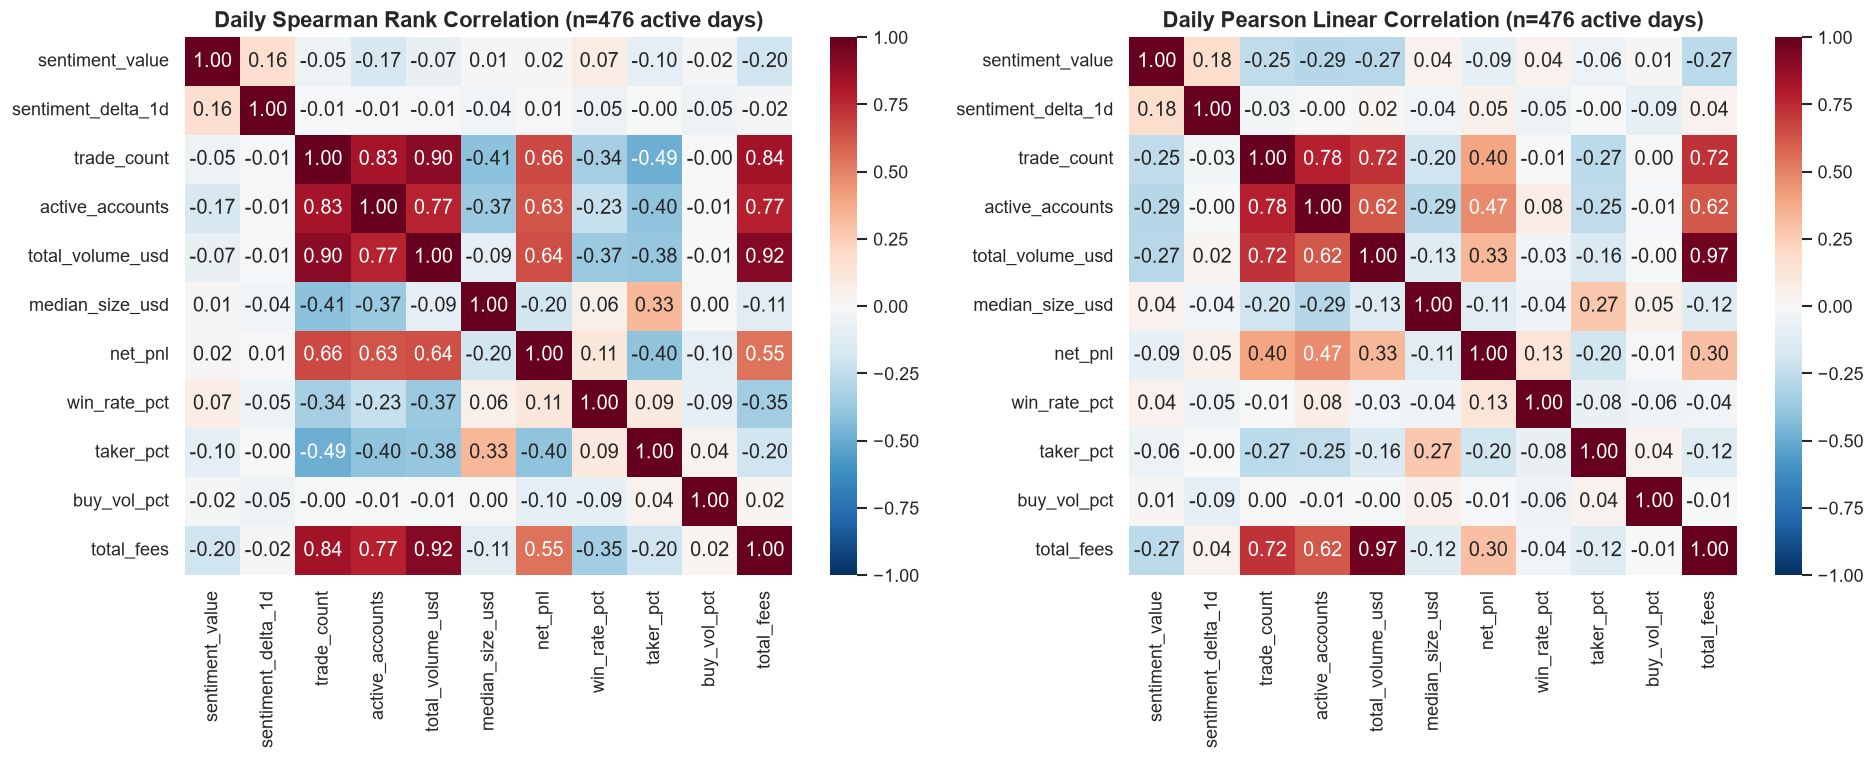

,lag_days,total_volume_usd,trade_count,net_pnl,win_rate_pct,taker_pct,buy_vol_pct
0,-5,-0.1072,-0.1094,-0.0273,0.0792,-0.0625,-0.0848
1,-4,-0.0914,-0.0946,-0.0134,0.0777,-0.0614,-0.0872
2,-3,-0.0888,-0.0863,-0.0129,0.0813,-0.0616,-0.1049
3,-2,-0.0924,-0.0814,-0.0032,0.0526,-0.0814,-0.1130
4,-1,-0.0973,-0.0759,0.0179,0.0891,-0.0846,-0.1104
5,0,-0.0707,-0.0501,0.0150,0.0722,-0.0994,-0.0206
6,1,-0.0561,-0.0408,0.0233,0.0908,-0.1033,0.0011
7,2,-0.0656,-0.0445,0.0297,0.0752,-0.0951,0.0193
8,3,-0.0630,-0.0333,0.0189,0.0838,-0.1043,-0.0002
9,4,-0.0699,-0.0451,0.0223,0.1047,-0.1091,-0.0119


[Saved CSV] csv_files\03d_eda_lead_lag.csv | shape=(11, 7)
[Saved Image] outputs\05_eda_lead_lag_analysis.png


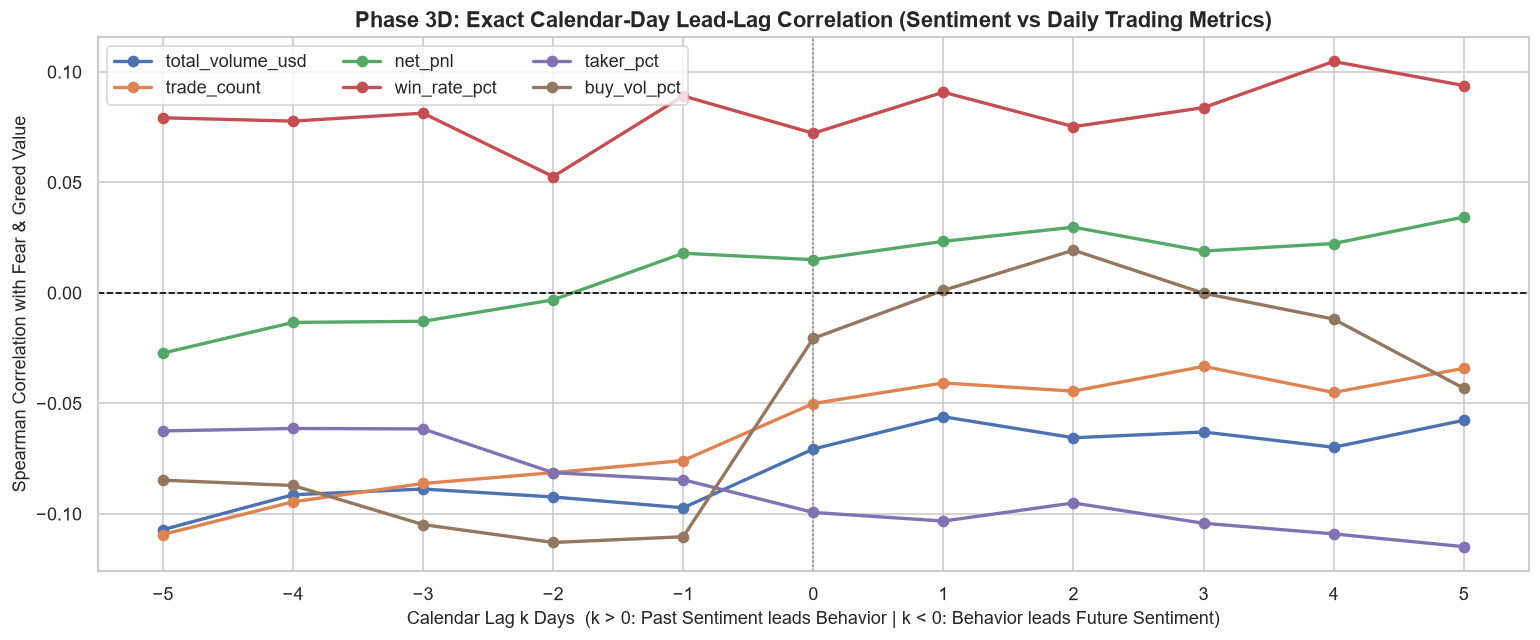

In [17]:
# 3D. Correlation & Calendar-Day Lead-Lag Analysis
daily_eda = (
    merged_df.groupby("trade_date_utc", as_index=False)
    .agg(
        sentiment_value=("sentiment_value", "first"),
        sentiment_delta_1d=("sentiment_delta_1d", "first"),
        trade_count=("account", "size"),
        active_accounts=("account", "nunique"),
        total_volume_usd=("size_usd", "sum"),
        median_size_usd=("size_usd", "median"),
        net_pnl=("closed_pnl", "sum"),
        total_fees=("fee", "sum"),
        taker_pct=("crossed", lambda s: 100.0 * s.mean()),
    )
)

# Add daily closing win rate & BUY volume share
daily_win = (
    merged_df[merged_df["is_closing_trade"]]
    .groupby("trade_date_utc", as_index=False)
    .agg(win_rate_pct=("closed_pnl", lambda s: 100.0 * (s > 0).mean()))
)
daily_buy = (
    merged_df.assign(buy_usd=np.where(merged_df["side"] == "BUY", merged_df["size_usd"], 0.0))
    .groupby("trade_date_utc", as_index=False)
    .agg(buy_usd=("buy_usd", "sum"), tot_usd=("size_usd", "sum"))
)
daily_buy["buy_vol_pct"] = 100.0 * daily_buy["buy_usd"] / daily_buy["tot_usd"].replace(0, np.nan)

daily_eda = (
    daily_eda.merge(daily_win, on="trade_date_utc", how="left")
    .merge(daily_buy[["trade_date_utc", "buy_vol_pct"]], on="trade_date_utc", how="left")
    .sort_values("trade_date_utc")
    .reset_index(drop=True)
)

corr_cols = [
    "sentiment_value", "sentiment_delta_1d", "trade_count", "active_accounts",
    "total_volume_usd", "median_size_usd", "net_pnl", "win_rate_pct",
    "taker_pct", "buy_vol_pct", "total_fees",
]
spearman_mat = daily_eda[corr_cols].corr(method="spearman")
pearson_mat = daily_eda[corr_cols].corr(method="pearson")

corr_export = pd.DataFrame({
    "metric": corr_cols,
    "spearman_vs_sentiment": [round(float(spearman_mat.loc[c, "sentiment_value"]), 4) for c in corr_cols],
    "pearson_vs_sentiment": [round(float(pearson_mat.loc[c, "sentiment_value"]), 4) for c in corr_cols],
})
display(corr_export)
export_csv(corr_export, "03d_eda_correlations.csv")

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
sns.heatmap(spearman_mat, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title(f"Daily Spearman Rank Correlation (n={len(daily_eda)} active days)")
sns.heatmap(pearson_mat, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title(f"Daily Pearson Linear Correlation (n={len(daily_eda)} active days)")
plt.tight_layout()
save_fig(fig, "05_eda_correlation_heatmap.png")
plt.show()

# Exact calendar-day lead-lag cross-correlation (on clean_sent calendar before joining)
sent_lags = clean_sent[["sentiment_date_str", "value"]].sort_values("sentiment_date_str").copy()
lags = list(range(-5, 6))
for k in lags:
    # k > 0 => past sentiment (t - k days) vs today's behavior (t)
    sent_lags[f"sent_lag_{k}"] = sent_lags["value"].shift(k)

daily_lag_df = daily_eda.merge(
    sent_lags.rename(columns={"sentiment_date_str": "trade_date_utc"}), on="trade_date_utc", how="left"
)

target_metrics = ["total_volume_usd", "trade_count", "net_pnl", "win_rate_pct", "taker_pct", "buy_vol_pct"]
lag_rows = []
for k in lags:
    row = {"lag_days": k}
    for m in target_metrics:
        valid = daily_lag_df[[f"sent_lag_{k}", m]].dropna()
        row[m] = round(float(valid[f"sent_lag_{k}"].corr(valid[m], method="spearman")), 4) if len(valid) > 10 else np.nan
    lag_rows.append(row)

lead_lag_df = pd.DataFrame(lag_rows)
display(lead_lag_df)
export_csv(lead_lag_df, "03d_eda_lead_lag.csv")

fig, ax = plt.subplots(figsize=(13, 5.5))
for m in target_metrics:
    ax.plot(lead_lag_df["lag_days"], lead_lag_df[m], marker="o", linewidth=2, label=m)
ax.axhline(0, color="black", linewidth=1, linestyle="--")
ax.axvline(0, color="gray", linewidth=1, linestyle=":")
ax.set_xticks(lags)
ax.set_xlabel("Calendar Lag k Days  (k > 0: Past Sentiment leads Behavior | k < 0: Behavior leads Future Sentiment)")
ax.set_ylabel("Spearman Correlation with Fear & Greed Value")
ax.set_title("Phase 3D: Exact Calendar-Day Lead-Lag Correlation (Sentiment vs Daily Trading Metrics)")
ax.legend(ncol=3, loc="best")
plt.tight_layout()
save_fig(fig, "05_eda_lead_lag_analysis.png")
plt.show()

---
## 4. Phase 4: Feature Engineering & Behavioral/Risk Metrics

- Engineer trade-level enriched metrics (`notional_usd`, `return_on_notional`, `risk_adjusted_pnl`, regime streak & lagged features).
- Build daily aggregated dataset -> `csv_files/03_features_daily_regime.csv`.
- Build trader-level behavioral profile dataset -> `csv_files/04_features_trader_profiles.csv`.
- Save feature distributions and summary table images (`outputs/06_features_*.png`).

In [ ]:
# TODO: Implement Phase 4 feature engineering and export processed feature CSVs